# Evaluating quantum machine unlearning under data poisoning
**Phase 1 research workflow**

Muhammad Danish Zaheer, Ahmed Adil, and Sarmad Ali

This notebook follows the research from data preparation and clean baselines through poisoning, unlearning, and evaluation. The implemented Phase 1 stages cover data preparation, clean and poisoned training, matched retained-data references, guided/uniform unlearning, and report exports. The unpoisoned quantum model is our gold reference. Phase 2 remains deferred. **The 420-image, exact-expectation, five-fold experiment is complete. Default execution now reviews its saved Linux/RTX 3070 results on Windows without retraining. Keep `SAVED_RESULTS_ONLY=True`, restart the kernel, and Run All.**

Run the active sections in order. The circuit, every generated figure, and analysis tables appear here beside their interpretation notes. Sections 8, 9, and 14 save copies for the report. All five folds are enabled in Section 12.1. Additional ablations, controls, sweeps, and hardware execution have disabled flags; Phase 2 remains empty.

1. Research question
2. Environment and GPU check
3. Experiment settings
4. Data, fixed folds, and preprocessing
5. Classical baselines
6. Quantum circuit and forward check
7. Gold reference model: clean training and evaluation
8. Save outputs and discuss results
9. Poisoned-dataset preparation
10. Poisoned training and retained-data references
11. Guided and uniform unlearning
12. All-fold evaluation, then optional ablations, controls, noise, and shots
13. Optional IBM evaluation
14. Evidence and report exports
15. Phase 2 (deferred)


## 1. Research question

Can Malik et al.'s distribution-guided, class-level unlearning method suppress digit 2 while preserving performance on digits 0 and 1 when the original model was trained on poisoned data?

**Motivation.** The method derives its forgetting and preservation targets from the trained model. Poisoning could affect those targets as well as the model. Chen and Zhang motivate studying poisoning and unlearning together, but their task removes known corrupted records; ours forgets a whole class.

**Working hypothesis.** Poisoning can weaken the trade-off between forgetting digit 2 and retaining digits 0/1, relative to clean training. We will separate damage already present after poisoned training from changes caused by unlearning.

**What could contradict this?** If paired clean/poisoned runs show no consistent deterioration in forgetting, retention, or agreement with matched retraining across the planned rates and completed folds at seed 6304, the hypothesis is not supported in those conditions. Exact zero class-2 probability is not required.

The clean baselines check the data pipeline and model. The poisoning and unlearning experiments are needed to answer the full research question; clean accuracy alone cannot establish quantum advantage.

References: [Malik et al., supplied v2](Relevant_Papers/2601.04413v2.pdf) and [Chen and Zhang, supplied manuscript](Relevant_Papers/s41467-026-70420-4_reference.pdf). Our circuit is independently implemented from the paper; the private repository has not been used.

## 2. Environment and GPU check
### 2.1. Select the Python environment

Select the environment containing the packages in `requirements.txt`. Open this notebook from the project folder. Relative paths allow the folder to move from Windows to Linux.

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src" / "config.py").is_file():
    raise RuntimeError("Open this notebook with QML_Project as the working directory.")

print("Project:", PROJECT_ROOT)
print("Python:", sys.executable)

Project: C:\Users\DanishZaheer\Desktop\LUMS\Semester_3\QML\QML_Project
Python: C:\Users\DanishZaheer\anaconda3\envs\QML\python.exe


### 2.2. Check the physical GPU and Aer support

These are separate checks. `nvidia-smi` reports a visible NVIDIA GPU; `aer_devices` reports what the installed Aer build exposes. A missing NVIDIA report can also mean that `nvidia-smi` is unavailable. Actual simulator execution is checked in Section 6.

In [2]:
from src.artifacts import environment_info

environment = environment_info()
gpu_available_to_aer = "GPU" in environment["aer_devices"]

print("Operating system:", environment["platform"])
print("NVIDIA report:", environment["nvidia_gpu"] or "Not available")
print("Aer devices:", environment["aer_devices"])
print("Aer GPU advertised:", gpu_available_to_aer)

if not gpu_available_to_aer:
    print("This Aer environment will use CPU. Local simulation is still available.")

Operating system: Windows-11-10.0.26300-SP0
NVIDIA report: NVIDIA GeForce RTX 3060 Laptop GPU, 6144 MiB, 610.88
Aer devices: ['CPU']
Aer GPU advertised: False
This Aer environment will use CPU. Local simulation is still available.


**Interpretation.** An RTX GPU together with only `CPU` in Aer means this Aer environment does not expose GPU execution. Moving the folder alone will not enable it.

WSL2 is a possible route: configure compatible CUDA/driver support and a Linux Python environment with GPU-enabled Aer, then select its notebook kernel and repeat the check. Aer documents its prebuilt GPU package for x86-64 Linux; Microsoft documents CUDA access in WSL2. See the [Aer installation guide](https://qiskit.github.io/qiskit-aer/getting_started.html) and [Microsoft WSL CUDA guide](https://learn.microsoft.com/en-us/windows/ai/directml/gpu-cuda-in-wsl). This notebook does not install or move anything. A GPU is not automatically faster for a six-qubit circuit.

### 2.3. Import the notebook tools

Reusable algorithms remain in `src/`. This notebook calls them and displays their outputs.

In [3]:
from dataclasses import asdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.config import DEFAULT_SEED, DataConfig, CircuitConfig, BackendConfig, TrainingConfig
from src.artifacts import save_split_manifest, load_json, save_json, fingerprint
from src.data.preprocessing import prepare_fold_features
from src.experiments import run_classical_cv, run_clean_vqc

display(pd.Series(environment["packages"], name="Installed version").to_frame())
figures = {}  # Keep figure objects for export in Section 8.

,Installed version
qiskit,2.5.1
qiskit-aer,0.17.2
qiskit-ibm-runtime,0.48.0
numpy,2.5.2
scipy,1.18.1
scikit-learn,1.9.1
pandas,3.1.0
matplotlib,3.11.1
joblib,1.6.0


## 3. Experiment settings
### 3.1. Fix the protocol before inspecting test results

| Choice | Current protocol |
|---|---|
| Data | 420 MNIST images: 140 per digit (0/1/2), from the official training pool |
| Splits | Five fixed stratified outer folds; 20% of each outer training partition is validation |
| Features | Pixels divided by 255, four training-fitted PCA components, angles in [0, pi] |
| Classical models | Majority, logistic regression, linear SVM, RBF SVM on all five folds |
| Quantum model | Six qubits, two reuploads, three ansatz repetitions per reupload, 72 nominal weights |
| Quantum study | Clean, poisoned, retrained, and unlearned models on all five folds; seed 6304 |
| Simulator | Local Aer statevector, exact expectations (`shots=None`), no device noise |
| Training | 300 supervised updates, batch size 10, Adam with a cosine learning rate; 100 unlearning updates |
| Poisoning | Clean control; 5%, 10%, 20%, 30%, 40%, 50% of the eligible class for each attack |

Each fold has 268 training, 68 validation, and 84 test records (28 test images per digit). The official MNIST test pool remains unused. Test records do not fit preprocessing, select checkpoints, or calibrate unlearning. Fold 0 is shown step by step; Section 12.1 completes the other folds and provides the primary summary.

Exact expectations match Malik's noiseless simulation setting. MNIST, 420 images, and our fold design are our experimental choices, not a reproduction of Malik's dataset or split. Compare the new conditions within this protocol; several settings changed together relative to the pilot.


### 3.2. Control saved-results review and training

Keep `SAVED_RESULTS_ONLY=True` for this completed experiment. You can restart the Windows QML kernel and **Run All** to rebuild tables and figures without training. The saved report and baseline paths explicitly identify the original experiment; automatic training-cache environment matching is not used in this mode.

Keep `FORCE_RETRAIN`, `DOWNLOAD_MNIST`, `RUN_QUANTUM_TRAINING`, and `REMOVE_PILOT_CHECKPOINTS` **False**. Section 10 also keeps training, unlearning, and optional experiments disabled. `RUN_FOLD_STUDY=True` loads all five saved folds for analysis.

The preflight check below verifies completed model files and stops on missing or incompatible artifacts. Classical baselines are loaded explicitly too. No estimator or PCA is fitted in review mode. Figures and analysis exports are regenerated separately from the original report; training records and checkpoints are preserved.

Keep seed **6304** and the original scientific settings. Historical training remains attributed to Linux/RTX 3070; current environment details describe Windows analysis. Future new experiments require leaving review mode, restarting the kernel, and deliberately enabling the relevant fitting flags. Source and environment changes still invalidate automatic training/resume caches.


In [4]:
from src.checkpoints import CheckpointSession, retire_pilot_checkpoints

SAVED_RESULTS_ONLY = True  # Safe on Windows: no model fitting or resume.
SAVED_REPORT = "results/tables/phase1_0e7dbe83c914e5f8"
SAVED_GOLD_RUN = "results/runs/clean_vqc/none_p0_seed6304_fold0_69a3d2f1241a062b"
SAVED_CLASSICAL_RUN = "results/runs/classical_cv/none_p0_seed6304_fold0_b128bae01a1a3d4d"

SEED = DEFAULT_SEED  # Fixed project seed: 6304.
DOWNLOAD_MNIST = False  # Reuse the downloaded dataset.
RUN_QUANTUM_TRAINING = False  # Load the saved gold model only.
REMOVE_PILOT_CHECKPOINTS = False  # Cleanup already completed; preserve saved files.
FORCE_RETRAIN = False  # True: start fresh; False: load completed / resume interrupted models.
checkpoints = CheckpointSession(force_retrain=FORCE_RETRAIN)


In [5]:
data_config = DataConfig(
    train_per_class=140,
    test_per_class=None,  # Unused: outer test folds come from the selected pool.
    split_strategy="stratified_kfold",
    n_folds=5,
    fold=0,
    validation_fraction=0.2,
    seed=SEED,
)


### 3.3. Configure local simulation and optimization

`device="auto"` uses GPU when Aer exposes it, otherwise CPU. GPU execution failures can fall back to CPU and are recorded. The 4,096 MB memory limit leaves headroom on the 6 GB laptop GPU; it is a simulator limit, not a GPU-memory reservation.

`shots=None` evaluates exact expectation values and removes measurement sampling noise. Setting `method="statevector"` alone would still sample if a finite shot count were supplied. IBM execution stays disabled.

In [6]:
circuit_config = CircuitConfig(reuploads=2, ansatz_reps=3)

backend_config = BackendConfig(
    shots=None,  # Exact expectations, without shot sampling.
    device="auto",
    method="statevector",
    circuit_batch_size=128,
    max_memory_mb=4096,
    max_parallel_threads=4,
    allow_cpu_fallback=True,
    use_ibm_hardware=False,
)


In [7]:
training_config = TrainingConfig(
    steps=300,             # One step is a mini-batch update, not an epoch.
    batch_size=10,
    learning_rate=0.02,
    minimum_learning_rate=0.001,
    initialization_std=0.1,
    evaluate_every=10,
    patience=None,         # Keep the full declared budget.
)

### 3.4. Load and verify the completed experiment

`SAVED_RESULTS_ONLY=True` reads the explicitly selected Linux experiment on this machine. It verifies saved artifacts, restores original splits/features, and blocks training, unlearning optimization, downloads, and new quantum predictions. A missing or incompatible saved result stops execution. Current Windows details describe the review environment; saved Linux/GPU details describe training. Restart the kernel before changing execution mode.

In [8]:
from src.evaluation.saved_results import (
    SavedResultsReview, protect_review, require_review_flags,
)

review = None
if SAVED_RESULTS_ONLY:
    require_review_flags(FORCE_RETRAIN=FORCE_RETRAIN, DOWNLOAD_MNIST=DOWNLOAD_MNIST,
                        RUN_QUANTUM_TRAINING=RUN_QUANTUM_TRAINING,
                        REMOVE_PILOT_CHECKPOINTS=REMOVE_PILOT_CHECKPOINTS)
    review_guard = protect_review()  # Remains active until the kernel is restarted.
    review = SavedResultsReview(PROJECT_ROOT, SAVED_REPORT,
                               gold_run=SAVED_GOLD_RUN, classical_run=SAVED_CLASSICAL_RUN)
    for name, setting in (("data", data_config), ("circuit", circuit_config),
                          ("backend", backend_config), ("training", training_config)):
        if fingerprint(asdict(setting)) != fingerprint(review.gold["config"][name]):
            raise ValueError(f"Review settings differ from the saved gold model: {name}")
    print(f"Verified {len(review.conditions)} conditions and {review.stage_run_count} model stages.")
    print("Saved baseline runs loaded too. Model fitting and checkpoint continuation are blocked.")

Verified 65 conditions and 230 model stages.
Saved baseline runs loaded too. Model fitting and checkpoint continuation are blocked.


In [9]:
if SAVED_RESULTS_ONLY:
    training_environment = review.gold["manifest"]["identity"]["environment"]
    display(pd.DataFrame({
        "Original training": {"OS": training_environment["platform"],
                              "Python": training_environment["python"],
                              "GPU": training_environment["nvidia_gpu"]},
        "Current review": {"OS": environment["platform"],
                           "Python": environment["python"],
                           "GPU": environment["nvidia_gpu"]},
    }))

,Original training,Current review
OS,Linux-7.0.0-31-generic-x86_64-with-glibc2.39,Windows-11-10.0.26300-SP0
Python,3.12.3,3.12.14
GPU,"NVIDIA GeForce RTX 3070 Laptop GPU, 8192 MiB, ...","NVIDIA GeForce RTX 3060 Laptop GPU, 6144 MiB, ..."


### 3.5. Retire incompatible pilot checkpoints once

When executed, this cell removes old model weights, optimizer progress, and fitted classifier files for the previous protocol. Metrics, predictions, histories, preprocessing, data, and report figures remain as pilot evidence. Retired runs cannot resume or serve as model imports. The one-time journal preserves original manifests; new 420-image/exact checkpoints are protected, including on repeated notebook runs.


In [10]:
if REMOVE_PILOT_CHECKPOINTS:
    cleanup = retire_pilot_checkpoints(
        PROJECT_ROOT, data_config=data_config, backend_config=backend_config, seed=SEED,
    )
    print("Pilot checkpoint cleanup:", cleanup["status"])
    print("Retired pilot run folders:", len(cleanup["targets"]))
    print("Journal: results/maintenance/mnist420_exact_v1.json")
else:
    print("Pilot checkpoint cleanup disabled.")

Pilot checkpoint cleanup disabled.


## 4. Data, fixed folds, and preprocessing
### 4.1. Load the original data

The loader checks the MNIST archive checksum and selects digits 0/1/2. Raw downloads go to `data/raw/`. Every image retains its original sample ID so later poisoning and forgetting can be traced.

In [11]:
from src.data.dataset import load_mnist, balanced_subset, make_cv_splits

train_pool, official_test_pool = load_mnist(
    PROJECT_ROOT / "data" / "raw", download=DOWNLOAD_MNIST,
)
pool = balanced_subset(train_pool, per_class=data_config.train_per_class, seed=data_config.seed)

print("Selected development pool:", len(pool))
print("Official test records reserved and unused:", len(official_test_pool))
display(pd.Series(pool.labels).value_counts().sort_index().rename("Records").to_frame())

Selected development pool: 420
Official test records reserved and unused: 3147


,Records
0,140
1,140
2,140


### 4.2. Create and save fixed folds

Stratification keeps digit proportions similar across partitions. Validation selects the quantum checkpoint; the outer test fold is evaluated afterward. Save partition IDs so later experiments use the same records.

In [12]:
if SAVED_RESULTS_ONLY:
    folds = review.restore_splits(train_pool)
    split_files = [review.split_paths[index] for index in range(data_config.n_folds)]
    splits = folds[data_config.fold]
    assert set(pool.sample_ids) == set(np.concatenate([fold.test.sample_ids for fold in folds]))
    print("Restored original split manifests:", len(split_files))
else:
    folds = make_cv_splits(
        pool,
        n_folds=data_config.n_folds,
        validation_fraction=data_config.validation_fraction,
        seed=data_config.seed,
    )
    split_files = [
        save_split_manifest(fold, PROJECT_ROOT / "data" / "splits")
        for fold in folds
    ]
    splits = folds[data_config.fold]
    print("Saved split manifests:", len(split_files))


Restored original split manifests: 5


### 4.3. Check membership and class counts

Every selected record should appear in exactly one outer test fold. Within each fold, train/validation/test IDs must be disjoint. These checks stop execution if partitions are inconsistent.

In [13]:
outer_test_ids = np.concatenate([fold.test.sample_ids for fold in folds])
assert len(np.unique(outer_test_ids)) == len(outer_test_ids) == len(pool)
assert set(outer_test_ids) == set(pool.sample_ids)

for fold in folds:
    train_ids = set(fold.train.sample_ids)
    validation_ids = set(fold.validation.sample_ids)
    test_ids = set(fold.test.sample_ids)
    assert train_ids.isdisjoint(validation_ids)
    assert train_ids.isdisjoint(test_ids)
    assert validation_ids.isdisjoint(test_ids)

print("Split membership checks passed.")

Split membership checks passed.


In [14]:
split_rows = []
for fold_index, fold in enumerate(folds):
    for partition_name in ("train", "validation", "test"):
        partition = getattr(fold, partition_name)
        counts = np.bincount(partition.labels, minlength=3)
        split_rows.append({
            "fold": fold_index, "partition": partition_name, "total": len(partition),
            "digit_0": counts[0], "digit_1": counts[1], "digit_2": counts[2],
        })

split_table = pd.DataFrame(split_rows)
display(split_table)

,fold,partition,total,digit_0,digit_1,digit_2
0,0,train,268,90,89,89
1,0,validation,68,22,23,23
2,0,test,84,28,28,28
3,1,train,268,90,89,89
4,1,validation,68,22,23,23
5,1,test,84,28,28,28
6,2,train,268,90,89,89
7,2,validation,68,22,23,23
8,2,test,84,28,28,28
9,3,train,268,90,89,89


### 4.4. Inspect training examples and the selected fold

The examples come only from the selected fold's training partition. Check that image content matches the labels and that all three digits are represented.


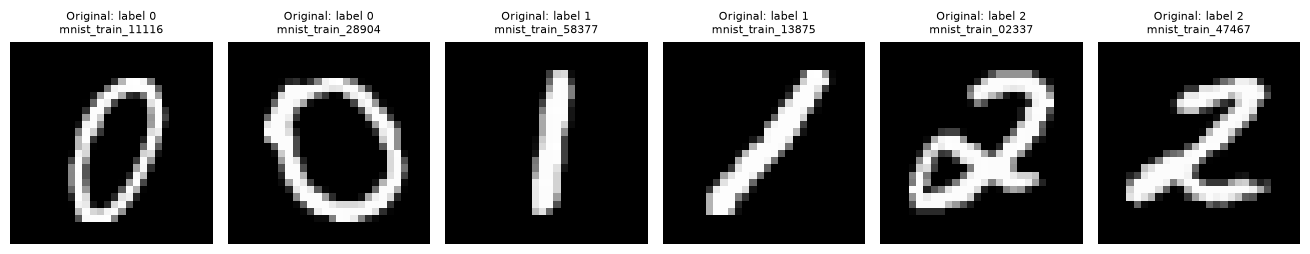

In [15]:
from src.evaluation.plots import (
    plot_examples, plot_class_balance, plot_pca_variance,
    plot_training_history, draw_circuit, save_figure,
)

example_indices = np.concatenate([
    np.flatnonzero(splits.train.labels == digit)[:2] for digit in (0, 1, 2)
])
figure = plot_examples(splits.train, indices=example_indices)
figures["training_examples"] = figure
display(figure)
plt.close(figure)

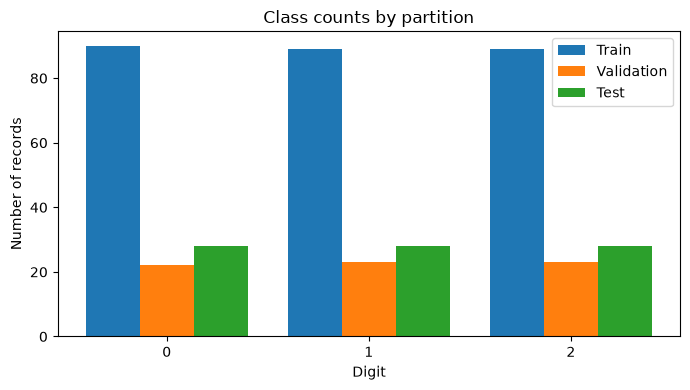

In [16]:
figure = plot_class_balance({
    "Train": splits.train.labels,
    "Validation": splits.validation.labels,
    "Test": splits.test.labels,
})
figures["selected_fold_counts"] = figure
display(figure)
plt.close(figure)

### 4.5. Fit preprocessing using training records only

The helper divides pixels by 255, fits four PCA components, and fits an angle scaler. Validation/test images only use `transform`. Values outside the fitted range are clipped to [0, pi].

Each fold gets a separate transformer. Classical and quantum models on the same fold use the same fitting rule, records, and seed.

In [17]:
if SAVED_RESULTS_ONLY:
    fold_features = review.gold_features(splits)  # Saved numeric arrays; no PCA refitting.
else:
    fold_features = prepare_fold_features(splits, seed=data_config.seed)
preprocessing = fold_features["preprocessing"]

X_train = fold_features["train"]
X_validation = fold_features["validation"]
X_test = fold_features["test"]

assert set(preprocessing.fit_sample_ids_) == set(splits.train.sample_ids)
assert X_train.shape == (len(splits.train), 4)
assert all(np.isfinite(values).all() for values in (X_train, X_validation, X_test))
print("Feature shapes:", X_train.shape, X_validation.shape, X_test.shape)


Feature shapes: (268, 4) (68, 4) (84, 4)


,angle_0,angle_1,angle_2,angle_3
0,1.570717,0.921723,0.694731,1.516879
1,1.592040,2.045248,0.619754,1.328030
2,1.924897,1.893200,1.731793,1.374468
3,2.117911,2.272549,2.027077,1.415130
4,3.019319,0.554008,1.220949,2.407993


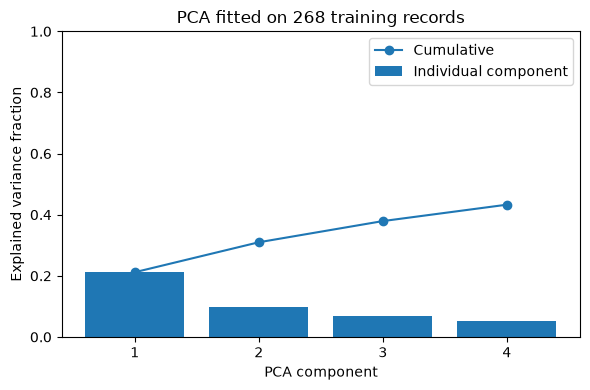

In [18]:
display(pd.DataFrame(X_train[:5], columns=["angle_0", "angle_1", "angle_2", "angle_3"]))

figure = plot_pca_variance(preprocessing)
figures["pca_variance"] = figure
display(figure)
plt.close(figure)

### 4.6. Quantify the retained variance

The table gives the fraction of training-pixel variance explained by each PCA component and the cumulative fraction shown in the plot above. These numbers describe compression of this fold's training data.


In [19]:
variance_ratio = preprocessing.pca.explained_variance_ratio_
pca_variance_table = pd.DataFrame({
    "component": np.arange(1, len(variance_ratio) + 1),
    "explained_variance_ratio": variance_ratio,
    "cumulative_variance_ratio": np.cumsum(variance_ratio),
})
display(pca_variance_table.round(4))


,component,explained_variance_ratio,cumulative_variance_ratio
0,1,0.2118,0.2118
1,2,0.0980,0.3098
2,3,0.0693,0.3791
3,4,0.0537,0.4328


**Interpretation.** The PCA plot shows training-pixel variation retained in four components. High explained variance does not guarantee good classification. If classical models also perform poorly, the representation or sample budget may be a limitation. Use training/validation evidence for later changes, rather than tuning to test results.

## 5. Classical baselines
### 5.1. Fit four comparison models on all five folds

All models receive the same four features as the VQC. The majority model provides a basic reference. Logistic regression, linear SVM, and RBF SVM test whether the representation contains useful class information.

Hyperparameters are fixed in `src/models/classical.py`. SVM probabilities use internal calibration within the training partition; predictions use the largest class probability. Outer validation/test records never enter fitting or calibration. Models, preprocessing, predictions, and metrics are saved together.
In saved-results review, the original classical predictions and metrics are loaded directly; no classical estimator is fitted.


In [20]:
if SAVED_RESULTS_ONLY:
    classical_run = review.classical
else:
    classical_run = run_classical_cv(
        folds, data_config=data_config, seed=SEED,
        checkpoints=checkpoints, root=PROJECT_ROOT,
    )
baseline_scores = pd.read_csv(classical_run["path"] / "scores.csv")
print("Classical run:", classical_run["path"].relative_to(PROJECT_ROOT))


Classical run: results\runs\classical_cv\none_p0_seed6304_fold0_b128bae01a1a3d4d


### 5.2. Summarize classical results

Accuracy is the fraction of correct three-class predictions. Standard deviation below describes variation across fixed folds at one seed. It is not uncertainty across independent seeds or a confidence interval.

In [21]:
# Inspect each fold before averaging: model rankings may vary by split.
fold_accuracy = baseline_scores.pivot(index="fold", columns="model", values="accuracy")
display(fold_accuracy.round(3))


model,linear_svm,logistic,majority,rbf_svm
fold,,,,
0,0.940,0.917,0.333,0.940
1,0.964,0.929,0.333,0.964
2,0.952,0.952,0.333,0.988
3,0.917,0.893,0.333,0.964
4,0.929,0.929,0.333,0.940


In [22]:
classical_summary = baseline_scores.groupby("model").agg(
    mean_accuracy=("accuracy", "mean"),
    fold_sd=("accuracy", "std"),
    n_folds=("fold", "nunique"),
)
display(classical_summary.round(3))

,mean_accuracy,fold_sd,n_folds
model,,,
linear_svm,0.940,0.019,5
logistic,0.924,0.022,5
majority,0.333,0.000,5
rbf_svm,0.960,0.020,5


**Interpretation to complete after execution.** Which models improve over the majority reference? Are fold differences large? Strong classical performance is useful evidence about the representation. Report weak or unfavorable quantum results too.

## 6. Quantum circuit and forward check
### 6.1. Build the circuit from Malik et al.

Two feature-map/ansatz blocks act on six qubits. Four features enter the first four qubits. Each ansatz has three repetitions of trainable RY/RZ rotations and ring CNOTs. Z expectations on qubits 3/4/5 become logits for a three-class softmax.

There are 72 nominal trainable weights and four input symbols. The final six RZ angles are inactive for the ideal Z readout; they remain to preserve the reported architecture. These are constructed-circuit counts; compiled resources are saved with the training run.
The full parameterized circuit is drawn below, wrapped across rows for readability. Follow the wire labels between rows. The gate table counts operations before transpilation; it does not measure hardware noise or execution time.


In [23]:
from src.models.circuits import build_malik_circuit, circuit_resources

circuit = build_malik_circuit(circuit_config)
circuit_information = circuit_resources(circuit)
display(pd.Series({
    "qubits": circuit_information["qubits"],
    "depth_before_transpilation": circuit_information["depth"],
    "two_qubit_gates": circuit_information["two_qubit_gates"],
    "nominal_trainable_weights": circuit_config.n_parameters,
    "input_features": 4,
}, name="Value").to_frame())

,Value
qubits,6
depth_before_transpilation,66
two_qubit_gates,48
nominal_trainable_weights,72
input_features,4


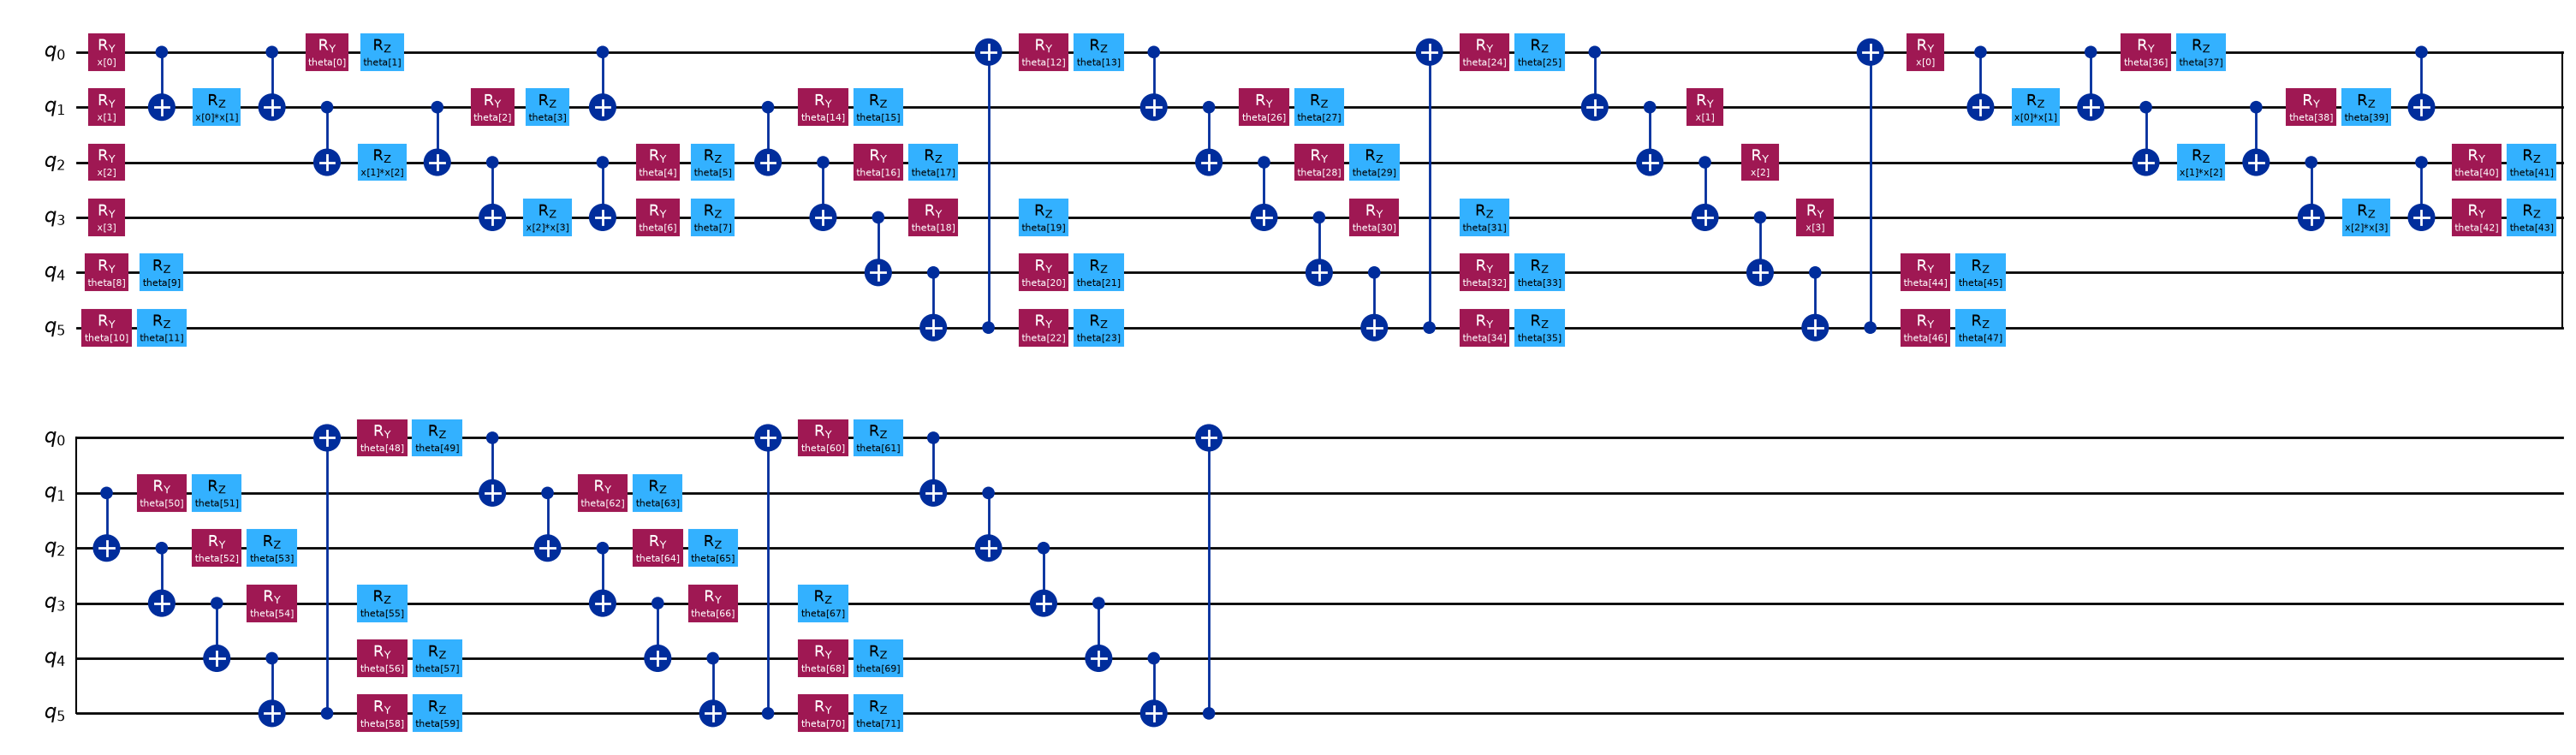

In [24]:
figure = draw_circuit(circuit, fold=45)
figures["quantum_circuit"] = figure
display(figure)
plt.close(figure)

In [25]:
gate_counts = pd.Series(
    circuit_information["operations"], name="count",
).rename_axis("gate").sort_index().to_frame()
display(gate_counts)


,count
gate,
cx,48
ry,44
rz,42


### 6.2. Check a small prediction batch

These are untrained random-weight predictions, not a trained-model result. Each row must contain three finite probabilities summing to one. This call also checks actual Aer execution.

The probe is separate from the training model so its samples do not consume the training run's random stream.

In [26]:
if SAVED_RESULTS_ONLY:
    probe_probabilities = review.gold["predictions"]["clean__test"][:3]
    print("Saved gold predictions for three test images; no new simulation.")
    display(pd.DataFrame(probe_probabilities, columns=["p(0)", "p(1)", "p(2)"]))
else:
    from src.models.vqc import VQC
    
    probe_model = VQC(circuit_config, backend_config, seed=SEED)
    initial_weights = np.random.default_rng(SEED).normal(
        0.0, training_config.initialization_std, circuit_config.n_parameters,
    )
    probe_probabilities = probe_model.predict_proba(X_train[:3], initial_weights)
    
    assert np.isfinite(probe_probabilities).all()
    assert np.all(probe_probabilities >= 0) and np.all(probe_probabilities <= 1)
    assert np.allclose(probe_probabilities.sum(axis=1), 1.0)
    display(pd.DataFrame(probe_probabilities, columns=["p(0)", "p(1)", "p(2)"]))


Saved gold predictions for three test images; no new simulation.


,p(0),p(1),p(2)
0,0.224989,0.513296,0.261715
1,0.385707,0.274983,0.339310
2,0.220170,0.496569,0.283261


In [27]:
if SAVED_RESULTS_ONLY:
    probe_resources = load_json(review.gold["path"] / "resources.json")
    print("Original gold training device:", probe_resources["actual_device"])
    print("This review uses saved predictions and performs no quantum simulation.")
else:
    probe_resources = probe_model.metadata()
    print("Probe execution device:", probe_resources["actual_device"])
    print("Probe expectation mode:", probe_resources["expectation_mode"])
    print("Fallback reason:", probe_resources["fallback_reason"] or "None")


Original gold training device: GPU
This review uses saved predictions and performs no quantum simulation.


### 6.3. Understand the training budget

The gradient shifts expectation values, then applies the classical softmax/cross-entropy chain rule. It does not shift the complete nonlinear loss.

Each gradient uses 1 + 2 x 72 circuit bindings per training example. This estimate excludes additional full training/validation checks and final test evaluation. Exact expectations remove measurement sampling noise, but parameter-shift training still requires many circuit evaluations. All-fold training can take substantial time even for six qubits.


In [28]:
bindings_per_example = 1 + 2 * circuit_config.n_parameters
batch_size = min(training_config.batch_size, len(splits.train))
gradient_bindings = training_config.steps * batch_size * bindings_per_example

print(f"Gradient circuit bindings: {gradient_bindings:,}")
if backend_config.shots is None:
    print("Gradient evaluations use exact expectations; no measurement shots are sampled.")
else:
    print(f"Gradient shot budget: {gradient_bindings * backend_config.shots:,}")
print("Additional evaluations are included in the saved resource counters.")

Gradient circuit bindings: 435,000
Gradient evaluations use exact expectations; no measurement shots are sampled.
Additional evaluations are included in the saved resource counters.


## 7. Gold reference model: clean training and evaluation
### 7.1. Train the selected-fold gold reference on clean data

This section trains or loads the gold reference for fold 0, seed 6304, so we can inspect one model step by step. Sections 10-11 reuse it for paired comparisons. Section 12.1 trains the corresponding models for the remaining folds; the final report summarizes all five folds.

Adam updates weights using training mini-batches. Validation loss selects the checkpoint, including initialization if it remains best. The clean test partition evaluates that checkpoint after training.

The gold reference learns digits 0, 1, and 2 using original, unpoisoned training images and labels. Its weights, history, predictions, and settings are saved under `results/runs/clean_vqc/`. Compatible completed runs are reused and interrupted runs resume.


In [29]:
def show_training_progress(row):
    # Every evaluation is saved; print only a few updates here.
    step = int(row["step"])
    if step % 50 == 0 or step == training_config.steps:
        print(
            f"Update {step:3d} | train loss {row['train_loss']:.4f} | "
            f"validation loss {row['validation_loss']:.4f}"
        )

In [30]:
# Confirm the one-model training plan before the training call.
assert splits.fingerprint() == folds[data_config.fold].fingerprint()
print(f"Gold reference: one clean VQC; fold {data_config.fold}; seed {SEED}.")
print(f"Records: {len(splits.train)} train, {len(splits.validation)} validation, {len(splits.test)} test.")
expectation_mode = "exact expectations" if backend_config.shots is None else f"{backend_config.shots} shots"
print(f"Budget: {training_config.steps} updates; batch size {training_config.batch_size}; {expectation_mode}.")
print(f"Local Aer device preference: {backend_config.device}; force retrain: {FORCE_RETRAIN}.")


Gold reference: one clean VQC; fold 0; seed 6304.
Records: 268 train, 68 validation, 84 test.
Budget: 300 updates; batch size 10; exact expectations.
Local Aer device preference: auto; force retrain: False.


In [31]:
if SAVED_RESULTS_ONLY:
    quantum_run = review.gold
else:
    quantum_run = run_clean_vqc(
        splits, data_config=data_config,
        circuit_config=circuit_config, backend_config=backend_config,
        training_config=training_config, seed=SEED,
        allow_training=RUN_QUANTUM_TRAINING,
        checkpoints=checkpoints, callback=show_training_progress,
        root=PROJECT_ROOT,
    )


In [32]:
# Clear old quantum plots if this section is rerun without a matching result.
for name in ("quantum_learning_curve", "quantum_confusion"):
    figures.pop(name, None)

if quantum_run is None:
    print("No matching quantum result. Enable RUN_QUANTUM_TRAINING and rerun Section 7 onward.")
else:
    print("Quantum run:", quantum_run["path"].relative_to(PROJECT_ROOT))
    print("Selected update:", quantum_run["manifest"]["best_step"])
    print("Best validation loss:", quantum_run["manifest"]["best_validation_loss"])

Quantum run: results\runs\clean_vqc\none_p0_seed6304_fold0_69a3d2f1241a062b
Selected update: 270
Best validation loss: 0.8316144994683221


### 7.2. Inspect the learning curve

Training loss reflects fit to training examples; validation loss selects the checkpoint. Falling training loss with rising validation loss can indicate overfitting. Flat curves can indicate an optimization or capacity limitation. Mini-batch training can produce non-monotonic losses even with exact expectations.
The table compares initialization, the checkpoint selected by validation loss, and the final recorded update. Two rows may refer to the same update. The loss gap is validation minus training loss; interpret it alongside the curves. Test performance never selects these rows.


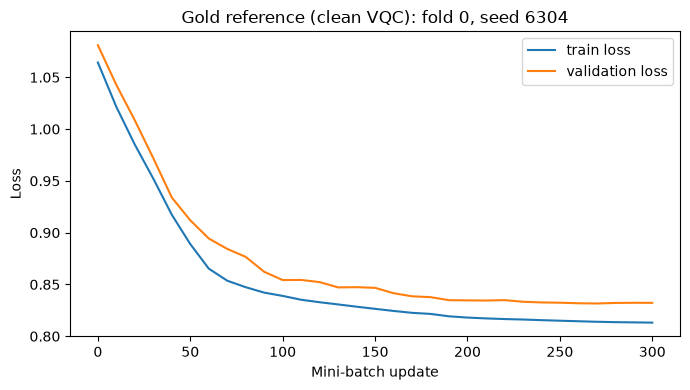

In [33]:
if quantum_run is not None:
    figure = plot_training_history(
        quantum_run["history"],
        title=f"Gold reference (clean VQC): fold {data_config.fold}, seed {SEED}",
    )
    figures["quantum_learning_curve"] = figure
    display(figure)
    plt.close(figure)

In [34]:
checkpoint_table = pd.DataFrame()
if quantum_run is not None:
    history = quantum_run["history"].set_index("step")
    selected_steps = [0, quantum_run["manifest"]["best_step"], history.index[-1]]
    checkpoint_table = history.loc[
        selected_steps, ["train_loss", "validation_loss", "elapsed_seconds"]
    ].copy()
    checkpoint_table.insert(0, "checkpoint", ["initial", "selected", "final"])
    checkpoint_table["validation_minus_train_loss"] = (
        checkpoint_table["validation_loss"] - checkpoint_table["train_loss"]
    )
    display(checkpoint_table.round(4))


,checkpoint,train_loss,validation_loss,elapsed_seconds,validation_minus_train_loss
step,,,,,
0,initial,1.0642,1.0810,0.4124,0.0167
270,selected,0.8140,0.8316,438.3065,0.0176
300,final,0.8131,0.8322,485.9289,0.0191


### 7.3. Compare on the same held-out records

Compare the first VQC with classical models on this same fold, rather than comparing its single score with a five-fold average.

Values are fractions from 0 to 1. Retained accuracy uses true digits 0/1 with normal three-class predictions. Digit-2 recall measures correct classification of digit 2. Before unlearning, high digit-2 recall is desirable: the model needs learned behavior to forget later.

In [35]:
comparison_columns = ["model", "n_test", "accuracy", "retained_accuracy", "digit_2_recall"]
same_fold_comparison = baseline_scores.loc[
    baseline_scores["fold"] == data_config.fold, comparison_columns
].copy()

In [36]:
if quantum_run is not None:
    quantum_metrics = quantum_run["metrics"]["models"]["clean"]
    quantum_row = {
        "model": "gold_reference", "n_test": quantum_metrics["n_samples"],
        "accuracy": quantum_metrics["accuracy"],
        "retained_accuracy": quantum_metrics["retained_accuracy"],
        "digit_2_recall": quantum_metrics["forget_recall"],
    }
    same_fold_comparison = pd.concat(
        [same_fold_comparison, pd.DataFrame([quantum_row])], ignore_index=True,
    )

display(same_fold_comparison.round(3))

,model,n_test,accuracy,retained_accuracy,digit_2_recall
0,majority,84,0.333,0.500,0.000
1,logistic,84,0.917,0.964,0.821
2,linear_svm,84,0.940,0.964,0.893
3,rbf_svm,84,0.940,0.982,0.857
4,gold_reference,84,0.917,0.964,0.821


### 7.4. Compare errors for each digit

Overall accuracy can hide a weak class. Compare all models on the same held-out fold: `n_test` is the number of examples of that true digit, `correct` and `errors` are counts, and `recall` is the fraction classified correctly. The gold reference appears only when its saved result exists.

Use this table to identify which digit is difficult and whether digit 2 is learned before any forgetting request. A difference of one or two examples in this small fold is limited evidence; report the counts alongside recall.


In [37]:
# Copy the saved metrics so this analysis does not alter the run records.
comparison_metrics = dict(classical_run["metrics"]["folds"][str(data_config.fold)])
if quantum_run is not None:
    comparison_metrics["gold_reference"] = quantum_metrics


In [38]:
class_rows = []
for model_name, metrics in comparison_metrics.items():
    confusion = np.asarray(metrics["confusion_matrix"])
    for digit in range(3):
        support = int(confusion[digit].sum())
        correct = int(confusion[digit, digit])
        class_rows.append({
            "model": model_name, "digit": digit, "n_test": support,
            "correct": correct, "errors": support - correct,
            "recall": metrics["recall_by_class"][str(digit)],
        })
per_class_comparison = pd.DataFrame(class_rows)
display(per_class_comparison.round(3))


,model,digit,n_test,correct,errors,recall
0,linear_svm,0,28,27,1,0.964
1,linear_svm,1,28,27,1,0.964
2,linear_svm,2,28,25,3,0.893
3,logistic,0,28,27,1,0.964
4,logistic,1,28,27,1,0.964
5,logistic,2,28,23,5,0.821
6,majority,0,28,28,0,1.000
7,majority,1,28,0,28,0.000
8,majority,2,28,0,28,0.000
9,rbf_svm,0,28,27,1,0.964


### 7.5. Inspect the quantum confusion matrix

Rows are true digits; columns are predicted digits. Diagonal entries are correct predictions. Check whether the model recognizes all three digits or mainly predicts one class. This plot appears only when a quantum result exists.

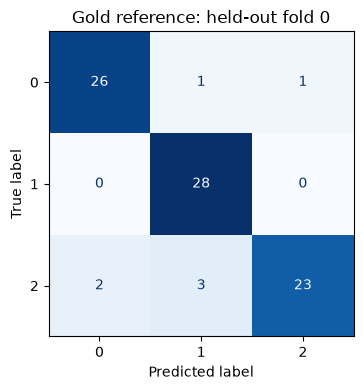

In [39]:
from sklearn.metrics import ConfusionMatrixDisplay

if quantum_run is not None:
    figure, axis = plt.subplots(figsize=(5, 4))
    ConfusionMatrixDisplay(
        np.asarray(quantum_metrics["confusion_matrix"]), display_labels=[0, 1, 2],
    ).plot(ax=axis, cmap="Blues", colorbar=False)
    axis.set_title(f"Gold reference: held-out fold {data_config.fold}")
    figure.tight_layout()
    figures["quantum_confusion"] = figure
    display(figure)
    plt.close(figure)

### 7.6. Record actual computation

Counters include training, full training/validation checks, and final test prediction. The separate probe is excluded. Training time excludes the final test call. Device and compiled-circuit details come from the saved run, including when reloaded.

In [40]:
resource_table = pd.DataFrame()
if quantum_run is not None:
    resources = load_json(quantum_run["path"] / "resources.json")
    resource_table = pd.DataFrame([{
        "device": resources["actual_device"],
        "method": resources["actual_method"],
        "qubits": resources["compiled_circuit"]["qubits"],
        "compiled_depth": resources["compiled_circuit"]["depth"],
        "two_qubit_gates": resources["compiled_circuit"]["two_qubit_gates"],
        "shots_per_circuit": resources["requested"]["shots"],
        "circuit_evaluations": resources["resources"]["circuit_evaluations"],
        "total_shots": resources["resources"]["shots"],
        "training_seconds": quantum_run["history"]["elapsed_seconds"].iloc[-1],
    }])
    display(resource_table)

,device,method,qubits,compiled_depth,two_qubit_gates,shots_per_circuit,circuit_evaluations,total_shots,training_seconds
0,GPU,statevector,6,66,48,None,445500,0,485.928868


## 8. Save outputs and discuss results
### 8.1. Export tables and figures

The helpers save settings, source/environment identity, record IDs, preprocessing, predictions, metrics, and model checkpoints in `results/runs/classical_cv/` and `results/runs/clean_vqc/`.

Every generated figure is displayed inline in its relevant section before export. The analysis tables are displayed there too. Export copies below so the same evidence is available for the report. PNG supports slides; PDF supports the report. Poisoned annotations are created in the poisoning stage.

In [41]:
source_runs = [classical_run["path"].relative_to(PROJECT_ROOT).as_posix()]
if quantum_run is not None:
    source_runs.append(quantum_run["path"].relative_to(PROJECT_ROOT).as_posix())

view_settings = {
    "source_runs": source_runs, "fold": data_config.fold,
    "circuit": asdict(circuit_config), "quantum_result_available": quantum_run is not None,
}
if SAVED_RESULTS_ONLY:
    view_settings.update(mode="saved_results_review", original_report=SAVED_REPORT,
                         review_environment=environment)
view_id = fingerprint(view_settings)[:16]
table_directory = PROJECT_ROOT / "results" / "tables" / view_id
figure_directory = PROJECT_ROOT / "results" / "figures" / view_id
table_directory.mkdir(parents=True, exist_ok=True)


In [42]:
split_table.to_csv(table_directory / "fixed_fold_counts.csv", index=False)
baseline_scores.to_csv(table_directory / "classical_fold_scores.csv", index=False)
classical_summary.to_csv(table_directory / "classical_summary.csv")
same_fold_comparison.to_csv(table_directory / "same_fold_comparison.csv", index=False)
if quantum_run is not None:
    resource_table.to_csv(table_directory / "quantum_resources.csv", index=False)

save_json(table_directory / "provenance.json", view_settings)
print("Tables:", table_directory.relative_to(PROJECT_ROOT))

Tables: results\tables\61ff0c343b19a8f1


In [43]:
# Export the additional displayed analysis tables without rounding.
pca_variance_table.to_csv(table_directory / "pca_variance.csv", index=False)
gate_counts.to_csv(table_directory / "circuit_gate_counts.csv")
fold_accuracy.to_csv(table_directory / "classical_accuracy_by_fold.csv")
per_class_comparison.to_csv(table_directory / "per_class_comparison.csv", index=False)
if quantum_run is not None:
    checkpoint_table.to_csv(table_directory / "quantum_checkpoints.csv")


In [44]:
for name, figure in figures.items():
    save_figure(
        figure, figure_directory / name,
        source_run_ids=source_runs,
        description=f"Clean baseline: {name.replace('_', ' ')}; selected fold {data_config.fold}.",
    )

save_json(figure_directory / "provenance.json", view_settings)
print("Figures:", figure_directory.relative_to(PROJECT_ROOT))

Figures: results\figures\61ff0c343b19a8f1


### 8.2. Discussion to complete after execution

- **Data:** did partition checks pass, and how much variance do four PCA components retain?
- **Classical models:** compare each fold before interpreting mean accuracy and fold standard deviation. Does the model ranking change across folds?
- **Gold reference:** compare initial, selected, and final losses. Record held-out accuracy and same-fold comparisons. Which digit has the most errors, and was digit 2 learned well enough to evaluate forgetting later?
- **Computation:** record actual device, shots, circuit evaluations, and training time.
- **Limitations:** this section illustrates one fold. Use Section 12.1 for all-fold conclusions; the small dataset, fixed seed, overlapping training folds, and ideal noiseless simulation remain limitations.
- **Next decision:** establish a usable clean baseline before interpreting forgetting. Investigate weak training using training/validation evidence.

**Discussion to complete from actual outputs.** The revised-protocol cells need execution; preserved pilot outputs are not new-protocol findings. Include unfavorable or inconclusive findings, and leave quantum conclusions pending until a trained result is available. Section 1 and Sections 3-7 provide introduction/methods material for the research report. The LaTeX report and GitHub submission are separate tasks.

## 9. Prepare poisoned training datasets

This section prepares data only. It creates a clean control and separate pixel-patch and label-flip variants for the selected fold. Poisoned-model training is implemented separately in Section 10.

Run Sections 2-4 first so the settings, original MNIST data, and fixed splits are available. Section 9 can run without training either the clean or poisoned models. It keeps images on their original 0-255 scale; fitting preprocessing for poisoned-model training comes later.

### 9.1. Set the poisoning conditions

Use 5%, 10%, 20%, 30%, 40%, and 50% of the **eligible training class**: digit 2 for pixel changes and digit 0 for label flips. These percentages differ from percentages of the whole training partition. Counts are rounded down; the tables below report both realized fractions. Small datasets may produce zero selected records.

The white 3-by-3 bottom-right patch is our configurable attack choice, not a pixel-level prescription reproduced from either paper. The same seed within each attack gives nested selected records as the rate increases.


In [45]:
from src.config import PoisonConfig
from src.data.poisoning import apply_poisoning
from src.artifacts import save_poisoned_dataset, source_fingerprint

POISON_RATES = (0.05, 0.10, 0.20, 0.30, 0.40, 0.50)
POISON_SEED = SEED
POISON_RATE_DENOMINATOR = "eligible"
PATCH_SIZE = 3
PATCH_VALUE = 255.0

assert POISON_RATES and len(set(POISON_RATES)) == len(POISON_RATES)
assert all(0 < rate <= 1 for rate in POISON_RATES)
assert POISON_RATE_DENOMINATOR in ("eligible", "all_training")


### 9.2. Reuse the selected training fold

All variants start from the same original training records. Validation and test data remain clean. The clean control records the zero-poison condition using the same annotation format. Re-run Section 4 after changing dataset size or fold settings.


In [46]:
clean_training = splits.train
assert splits.fingerprint() == folds[data_config.fold].fingerprint()
clean_partition_fingerprints = {
    name: getattr(splits, name).fingerprint() for name in ("train", "validation", "test")
}
poison_variants = {
    "clean": apply_poisoning(clean_training, PoisonConfig(seed=POISON_SEED))
}
poison_figures = {}  # Separate from the clean-model figures in Section 8.
print(f"Preparing fold {data_config.fold}: {len(clean_training)} training records.")


Preparing fold 0: 268 training records.


### 9.3. Add pixel patches to digit 2

Only selected digit-2 training images receive the patch. Their labels remain 2. Each rate starts from the original images, so patches do not accumulate across variants.


In [47]:
for rate in sorted(POISON_RATES):
    condition = f"pixel_patch_{100 * rate:g}pct"
    poison_config = PoisonConfig(
        kind="pixel_patch", rate=rate, denominator=POISON_RATE_DENOMINATOR,
        seed=POISON_SEED, target_class=2,
        patch_size=PATCH_SIZE, patch_value=PATCH_VALUE,
    )
    poison_variants[condition] = apply_poisoning(clean_training, poison_config)


### 9.4. Flip selected digit-0 labels to digit 2

The images stay unchanged. Only the observed training label changes from 0 to 2; original labels and sample IDs are retained for auditing. Pixel patches and label flips are separate conditions.


In [48]:
for rate in sorted(POISON_RATES):
    condition = f"label_flip_{100 * rate:g}pct"
    poison_config = PoisonConfig(
        kind="label_flip", rate=rate, denominator=POISON_RATE_DENOMINATOR,
        seed=POISON_SEED, source_class=0, target_class=2,
    )
    poison_variants[condition] = apply_poisoning(clean_training, poison_config)


### 9.5. Check record alignment and intended changes

These assertions check the prepared data before saving: stable IDs, correct counts, unchanged unselected records, and the intended attack. A failed check stops the section. Fingerprints also check that preparing the variants did not modify the original training, validation, or test data.


In [49]:
for condition, variant in poison_variants.items():
    np.testing.assert_array_equal(variant.observed.sample_ids, clean_training.sample_ids)
    assert variant.original.fingerprint() == clean_partition_fingerprints["train"]
    unchanged = ~variant.is_poisoned
    np.testing.assert_array_equal(variant.observed.images[unchanged], clean_training.images[unchanged])
    np.testing.assert_array_equal(variant.observed.labels[unchanged], clean_training.labels[unchanged])
    denominator = (variant.eligible_count if variant.config.denominator == "eligible"
                   else len(clean_training))
    expected_count = int(np.floor(variant.config.rate * denominator))
    assert int(variant.is_poisoned.sum()) == expected_count, condition


In [50]:
for condition, variant in poison_variants.items():
    selected = variant.is_poisoned
    if variant.config.kind == "pixel_patch":
        np.testing.assert_array_equal(variant.observed.labels, clean_training.labels)
        assert np.all(clean_training.labels[selected] == 2)
        size = variant.config.patch_size
        assert np.all(variant.observed.images[selected, -size:, -size:] == variant.config.patch_value)
        changed_positions = np.any(variant.observed.images != clean_training.images, axis=0)
        changed_positions[-size:, -size:] = False
        assert not changed_positions.any(), condition
    elif variant.config.kind == "label_flip":
        np.testing.assert_array_equal(variant.observed.images, clean_training.images)
        assert np.all(clean_training.labels[selected] == 0)
        assert np.all(variant.observed.labels[selected] == 2)


In [51]:
for attack in ("pixel_patch", "label_flip"):
    previous_ids = set()
    for rate in sorted(POISON_RATES):
        variant = poison_variants[f"{attack}_{100 * rate:g}pct"]
        selected_ids = set(variant.observed.sample_ids[variant.is_poisoned])
        assert previous_ids <= selected_ids, "Expected nested selected records."
        previous_ids = selected_ids

for partition, expected_fingerprint in clean_partition_fingerprints.items():
    assert getattr(splits, partition).fingerprint() == expected_fingerprint, partition
print("Checks passed: intended changes only; original partitions remain unchanged.")


Checks passed: intended changes only; original partitions remain unchanged.


### 9.6. Inspect requested rates, actual changes, and label balance

`selected_records` counts records chosen for the attack. `changed_images` counts actual pixel changes: a patch can have no effect if those pixels already equal the requested value. Label flips should change labels without changing images; pixel patches should preserve label counts.


In [52]:
poison_summary_rows = []
for condition, variant in poison_variants.items():
    information = variant.metadata()
    poison_summary_rows.append({
        "variant": condition, "n_training": len(clean_training),
        "eligible_records": information["eligible_count"],
        "selected_records": information["poisoned_count"],
        "requested_pct": 100 * variant.config.rate,
        "actual_eligible_pct": 100 * information["actual_fraction_eligible"],
        "actual_training_pct": 100 * information["actual_fraction_all_training"],
    })
poison_summary = pd.DataFrame(poison_summary_rows)
display(poison_summary.round(3))


,variant,n_training,eligible_records,selected_records,requested_pct,actual_eligible_pct,actual_training_pct
0,clean,268,89,0,0.0,0.000,0.000
1,pixel_patch_5pct,268,89,4,5.0,4.494,1.493
2,pixel_patch_10pct,268,89,8,10.0,8.989,2.985
3,pixel_patch_20pct,268,89,17,20.0,19.101,6.343
4,pixel_patch_30pct,268,89,26,30.0,29.213,9.701
5,pixel_patch_40pct,268,89,35,40.0,39.326,13.060
6,pixel_patch_50pct,268,89,44,50.0,49.438,16.418
7,label_flip_5pct,268,90,4,5.0,4.444,1.493
8,label_flip_10pct,268,90,9,10.0,10.000,3.358
9,label_flip_20pct,268,90,18,20.0,20.000,6.716


In [53]:
change_rows = []
for condition, variant in poison_variants.items():
    changed_images = np.any(variant.observed.images != clean_training.images, axis=(1, 2))
    changed_labels = variant.observed.labels != clean_training.labels
    change_rows.append({
        "variant": condition, "changed_images": int(changed_images.sum()),
        "changed_labels": int(changed_labels.sum()),
        "selected_without_change": int((variant.is_poisoned & ~changed_images & ~changed_labels).sum()),
    })
poison_changes = pd.DataFrame(change_rows)
display(poison_changes)


,variant,changed_images,changed_labels,selected_without_change
0,clean,0,0,0
1,pixel_patch_5pct,4,0,0
2,pixel_patch_10pct,8,0,0
3,pixel_patch_20pct,17,0,0
4,pixel_patch_30pct,26,0,0
5,pixel_patch_40pct,35,0,0
6,pixel_patch_50pct,44,0,0
7,label_flip_5pct,0,4,0
8,label_flip_10pct,0,9,0
9,label_flip_20pct,0,18,0


In [54]:
poison_label_counts = pd.DataFrame({
    condition: np.bincount(variant.observed.labels, minlength=3)
    for condition, variant in poison_variants.items()
}).T.rename_axis("variant").rename(columns={0: "digit_0", 1: "digit_1", 2: "digit_2"})
display(poison_label_counts)


,digit_0,digit_1,digit_2
variant,,,
clean,90,89,89
pixel_patch_5pct,90,89,89
pixel_patch_10pct,90,89,89
pixel_patch_20pct,90,89,89
pixel_patch_30pct,90,89,89
pixel_patch_40pct,90,89,89
pixel_patch_50pct,90,89,89
label_flip_5pct,86,89,93
label_flip_10pct,81,89,98


### 9.7. View clean and poisoned examples

Preview both attacks at the largest configured rate. Change `PREVIEW_RATE` to another configured rate to inspect it. Each column follows the same record before and after the change. These examples verify the data construction; they do not establish model damage or robustness.


In [55]:
from src.evaluation.plots import plot_examples, plot_class_balance, save_figure

PREVIEW_RATE = max(POISON_RATES)
assert PREVIEW_RATE in POISON_RATES
preview_conditions = [
    f"{attack}_{100 * PREVIEW_RATE:g}pct" for attack in ("pixel_patch", "label_flip")
]
poison_figures.clear()  # Avoid exporting old preview figures when this section is rerun.


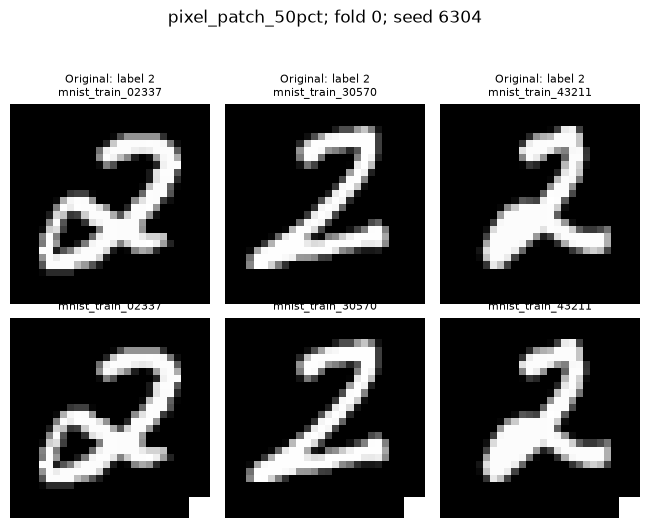

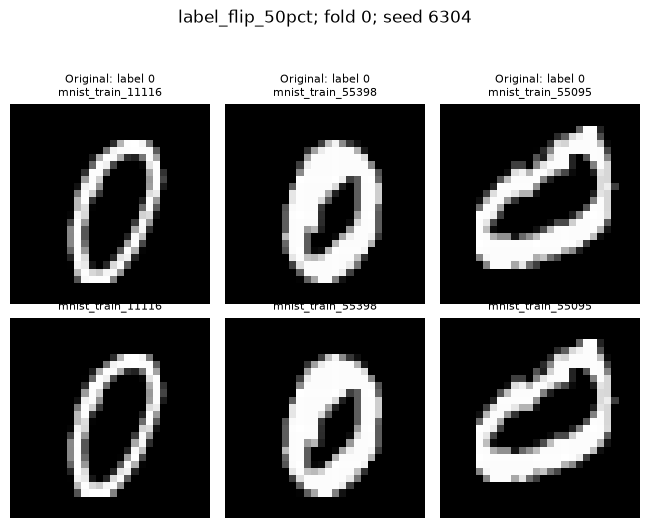

In [56]:
for condition in preview_conditions:
    variant = poison_variants[condition]
    example_indices = np.flatnonzero(variant.is_poisoned)[:3]
    if not len(example_indices):
        print(f"{condition}: no selected records at this dataset size.")
        continue
    figure = plot_examples(clean_training, variant.observed, indices=example_indices, max_examples=3)
    figure.suptitle(f"{condition}; fold {data_config.fold}; seed {POISON_SEED}")
    figure.tight_layout(rect=(0, 0, 1, 0.92))
    poison_figures[f"{condition}_examples"] = figure
    display(figure)
    plt.close(figure)


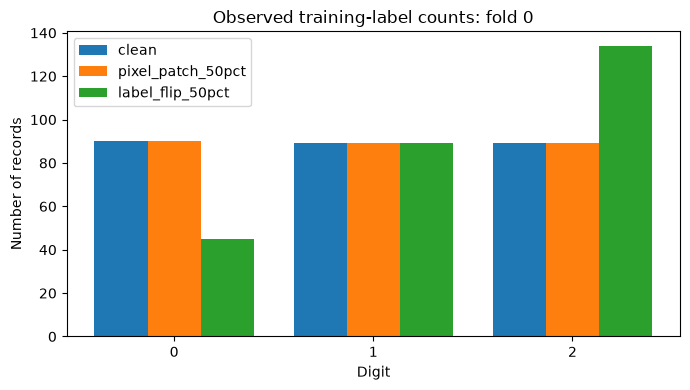

In [57]:
balance_partitions = {"clean": clean_training.labels}
for condition in preview_conditions:
    balance_partitions[condition] = poison_variants[condition].observed.labels
figure = plot_class_balance(balance_partitions)
figure.axes[0].set_title(f"Observed training-label counts: fold {data_config.fold}")
poison_figures["observed_label_counts"] = figure
display(figure)
plt.close(figure)


#### 9.7.1. Check exactly what changed

We prepare two separate poisoning conditions:

| Condition | Image change | Label change |
|---|---|---|
| Pixel patch | Add a white 3-by-3 patch at the bottom-right of selected digit-2 images. | Keep label 2. |
| Label flip | Keep the digit-0 image unchanged. | Change the observed training label from 0 to 2. |

Each row below follows one selected training record through **original image**, **poisoned image**, and **absolute pixel difference**. The orange outline marks the configured patch location; it is only a drawing annotation. The difference panel uses the same 0-255 scale for both attacks, so unchanged images show zero difference.

These detailed figures use `PREVIEW_RATE` from above (20% by default) and show up to three selected records per attack. They are displayed here and included in the Section 9.9 figure exports. Existing preview outputs above are preserved; run this new cell to display the detailed views.


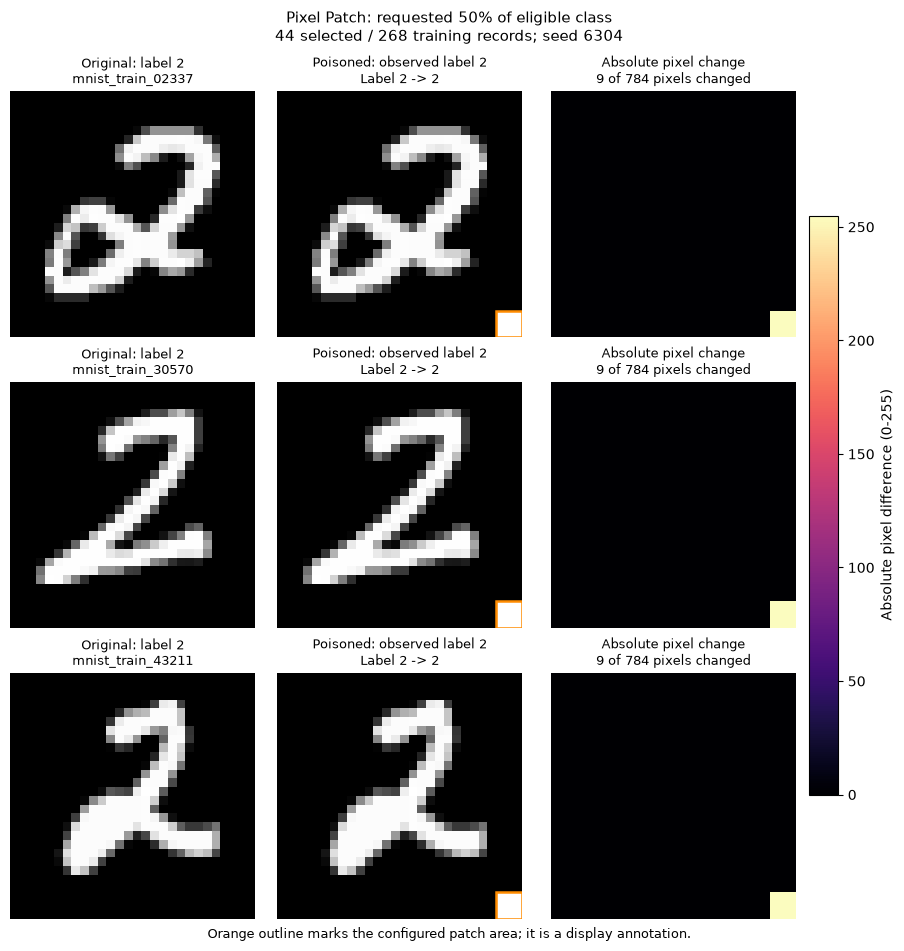

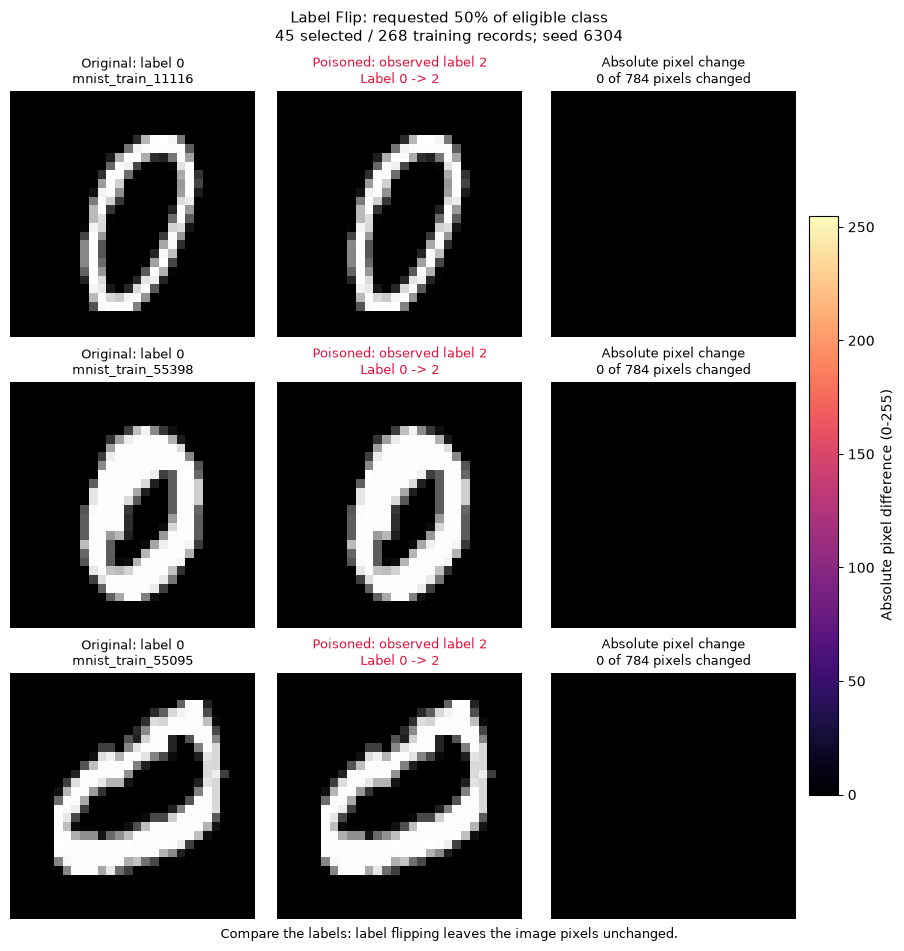

In [58]:
from src.evaluation.plots import plot_poisoned_examples

# Plot the prepared variants; this cell does not modify images or train models.
for condition in preview_conditions:
    variant = poison_variants[condition]
    if not variant.is_poisoned.any():
        print(f"{condition}: no selected records to display.")
        continue
    figure = plot_poisoned_examples(variant, max_examples=3)
    poison_figures[f"{condition}_pixel_differences"] = figure
    display(figure)
    plt.close(figure)


**How to read these figures:** for the pixel attack, check that differences are confined to the bottom-right patch and that both labels remain 2. A 3-by-3 patch changes at most 9 of the 784 pixels; fewer may change if some pixels already have the patch value. For the label attack, the two images should look identical and the difference panel should show zero changed pixels, while the label changes from 0 to 2.

Validation and test records stay clean. Visible corruption confirms data preparation; its effect after PCA, on classification, and on unlearning still requires later measurement.


### 9.8. Inspect annotations and future forget-set membership

Every saved record retains its original and observed label, sample ID, poison flag/type, and seed. The preview below shows up to three selected records per displayed attack; the saved CSV contains every training record.

The membership table shows both definitions of digit 2 for later analysis. Observed-label class forgetting would include digit-0 records relabeled as 2; original-label forgetting would exclude those digit-0 records. This is a data audit only: no records are deleted and no unlearning is performed.


In [59]:
annotation_preview = pd.concat([
    poison_variants[condition].manifest()
    .loc[poison_variants[condition].is_poisoned].head(3).assign(variant=condition)
    for condition in preview_conditions
], ignore_index=True)
display(annotation_preview)


,sample_id,original_label,observed_label,is_poisoned,poison_type,poison_seed,variant
0,mnist_train_02337,2,2,True,pixel_patch,6304,pixel_patch_50pct
1,mnist_train_30570,2,2,True,pixel_patch,6304,pixel_patch_50pct
2,mnist_train_43211,2,2,True,pixel_patch,6304,pixel_patch_50pct
3,mnist_train_11116,0,2,True,label_flip,6304,label_flip_50pct
4,mnist_train_55398,0,2,True,label_flip,6304,label_flip_50pct
5,mnist_train_55095,0,2,True,label_flip,6304,label_flip_50pct


In [60]:
membership_rows = []
for condition, variant in poison_variants.items():
    original_digit_2 = variant.original.labels == 2
    observed_digit_2 = variant.observed.labels == 2
    membership_rows.append({
        "variant": condition,
        "original_digit_2_records": int(original_digit_2.sum()),
        "observed_digit_2_records": int(observed_digit_2.sum()),
        "relabeled_0_in_observed_digit_2": int(((variant.original.labels == 0) & observed_digit_2).sum()),
    })
poison_membership = pd.DataFrame(membership_rows)
display(poison_membership)


,variant,original_digit_2_records,observed_digit_2_records,relabeled_0_in_observed_digit_2
0,clean,89,89,0
1,pixel_patch_5pct,89,89,0
2,pixel_patch_10pct,89,89,0
3,pixel_patch_20pct,89,89,0
4,pixel_patch_30pct,89,89,0
5,pixel_patch_40pct,89,89,0
6,pixel_patch_50pct,89,89,0
7,label_flip_5pct,89,93,4
8,label_flip_10pct,89,98,9
9,label_flip_20pct,89,107,18


### 9.9. Save annotated datasets and displayed analysis

Executing these cells creates `data/annotated/<condition>_p<percentage>_<fingerprint>/` with `images.npz`, `annotations.csv`, and `metadata.json`. The archive contains observed images, both label versions, stable IDs, and poison flags. Original images remain in `data/raw/mnist.npz` and are recoverable by their sample IDs.

A collection index under `data/annotated/collections/` links all variants to the exact split, settings, and source identity. Matching existing variants are reused; conflicting or incomplete folders raise an error. Displayed tables and figures are saved under `results/tables/poison_preparation_<id>/` and `results/figures/poison_preparation_<id>/`. These are data-preparation artifacts, with no model results.


In [61]:
poison_paths = {}
for condition, variant in poison_variants.items():
    if SAVED_RESULTS_ONLY:
        poison_paths[condition] = review.annotated_path(asdict(variant.config), data_config.fold)
    else:
        poison_paths[condition] = save_poisoned_dataset(variant, PROJECT_ROOT / "data" / "annotated")

poison_locations = pd.DataFrame([
    {"variant": condition, "directory": path.relative_to(PROJECT_ROOT).as_posix()}
    for condition, path in poison_paths.items()
])
display(poison_locations)


,variant,directory
0,clean,data/annotated/clean_p0_77632e1fd613153d
1,pixel_patch_5pct,data/annotated/pixel_patch_p5_4686f645beea9d92
2,pixel_patch_10pct,data/annotated/pixel_patch_p10_4c168383cd9a5053
3,pixel_patch_20pct,data/annotated/pixel_patch_p20_e06c680bea38b194
4,pixel_patch_30pct,data/annotated/pixel_patch_p30_bd5a339752f5bac3
5,pixel_patch_40pct,data/annotated/pixel_patch_p40_1b4397989c15c5ee
6,pixel_patch_50pct,data/annotated/pixel_patch_p50_97be1428d2a46833
7,label_flip_5pct,data/annotated/label_flip_p5_a05ed2a64b7e915a
8,label_flip_10pct,data/annotated/label_flip_p10_f0cdfbf4da787661
9,label_flip_20pct,data/annotated/label_flip_p20_e296ebb5e23d075c


In [62]:
# Verify saved arrays even when an existing variant directory is reused.
from src.artifacts import load_arrays

for condition, path in poison_paths.items():
    saved = load_arrays(path / "images.npz")
    variant = poison_variants[condition]
    np.testing.assert_array_equal(saved["images"], variant.observed.images)
    np.testing.assert_array_equal(saved["sample_ids"], clean_training.sample_ids)
    np.testing.assert_array_equal(saved["original_labels"], clean_training.labels)
    np.testing.assert_array_equal(saved["observed_labels"], variant.observed.labels)
    np.testing.assert_array_equal(saved["is_poisoned"], variant.is_poisoned)
print("Saved dataset arrays match the prepared variants.")


Saved dataset arrays match the prepared variants.


In [63]:
poison_split_file = (review.split_paths[data_config.fold] if SAVED_RESULTS_ONLY
                     else save_split_manifest(splits, PROJECT_ROOT / "data" / "splits"))
poison_provenance = {
    "stage": "poison_data_preparation", "data_config": asdict(data_config),
    "split_fingerprint": splits.fingerprint(),
    "split_manifest": poison_split_file.relative_to(PROJECT_ROOT).as_posix(),
    "variants": {name: path.relative_to(PROJECT_ROOT).as_posix() for name, path in poison_paths.items()},
    "poison_configs": {name: asdict(variant.config) for name, variant in poison_variants.items()},
    "source_fingerprint": source_fingerprint(), "packages": environment["packages"],
}
poison_collection_id = fingerprint(poison_provenance)[:16]
poison_collection_file = PROJECT_ROOT / "data" / "annotated" / "collections" / f"{poison_collection_id}.json"
if SAVED_RESULTS_ONLY:
    poison_provenance.update(mode="saved_results_review", original_report=SAVED_REPORT)
    poison_collection_file = PROJECT_ROOT / "results/reviews" / Path(SAVED_REPORT).name / "poison_collection.json"
save_json(poison_collection_file, poison_provenance)
print("Dataset collection:", poison_collection_file.relative_to(PROJECT_ROOT))


Dataset collection: results\reviews\phase1_0e7dbe83c914e5f8\poison_collection.json


In [64]:
# Include preview settings so exports from different previews have distinct folders.
poison_view = {"collection": poison_collection_file.relative_to(PROJECT_ROOT).as_posix(),
               "preview_rate": PREVIEW_RATE, "max_examples": 3}
poison_view_id = fingerprint(poison_view)[:16]
poison_table_directory = PROJECT_ROOT / "results" / "tables" / f"poison_preparation_{poison_view_id}"
poison_figure_directory = PROJECT_ROOT / "results" / "figures" / f"poison_preparation_{poison_view_id}"
poison_table_directory.mkdir(parents=True, exist_ok=True)
poison_tables = {
    "counts": poison_summary, "changes": poison_changes,
    "label_counts": poison_label_counts.reset_index(), "annotation_preview": annotation_preview,
    "forget_membership": poison_membership, "locations": poison_locations,
}


In [65]:
for name, table in poison_tables.items():
    table.to_csv(poison_table_directory / f"{name}.csv", index=False)
save_json(poison_table_directory / "provenance.json", poison_view)
print("Poison-preparation tables:", poison_table_directory.relative_to(PROJECT_ROOT))


Poison-preparation tables: results\tables\poison_preparation_5a65453c0692cbde


In [66]:
for name, figure in poison_figures.items():
    save_figure(
        figure, poison_figure_directory / name, source_run_ids=[],
        description=f"Data preparation: {name}; collection {poison_collection_id}; fold {data_config.fold}.",
    )
save_json(poison_figure_directory / "provenance.json", poison_view)
print("Poison-preparation figures:", poison_figure_directory.relative_to(PROJECT_ROOT))


Poison-preparation figures: results\figures\poison_preparation_5a65453c0692cbde


### 9.10. Interpret the prepared data

- Do the actual counts match the requested rate after rounding, and how much of the entire training partition is affected?
- Do pixel patches preserve labels, and do label flips preserve images while moving counts from digit 0 to digit 2?
- Are any selected patches ineffective? Do small counts limit the distinction between rates?
- How would original-label versus observed-label forgetting change the designated record set?

**Preparation is not a model result.** These checks establish what data was constructed. Damage to classification, quantum robustness, and unlearning outcomes remain questions for later experiments. Continue to Section 10 for poisoned-model preprocessing, training, and evaluation.


## 10. Poisoned model training and retained-data retraining

Run Sections 2-4 and 9 first. Section 7 supplies the existing clean gold model when available. This section trains the poisoned classifiers and matched retained-data references. Section 11 performs unlearning separately.

Each model has a saved checkpoint, fitted preprocessing, record IDs, predictions, and resource counts. Identical fitting problems are reused across conditions. The clean gold reference remains the unpoisoned three-class classifier.

### 10.1. Choose execution controls

The core training and unlearning flags below are now **False** for saved-results review: they load matching completed stages without fitting or resuming optimization. `RUN_FOLD_STUDY=True` stays enabled so Section 12.1 loads all five folds and rebuilds their analysis. It does not override the disabled fitting flags. Ablations, shuffled-label controls, noise/shot sweeps, and IBM execution remain disabled. Keep seed 6304 throughout.

`GOLD_REFERENCE_PATH` can explicitly select a trusted historical Section 7 run if code changes prevent automatic cache matching. Retired pilot runs cannot be imported. Its split, seed, circuit, backend, and training settings must match; its original provenance is preserved. Otherwise use `quantum_run` from Section 7. To reuse a historical run without running Section 7 training, first set `RUN_QUANTUM_TRAINING=False` in Section 3.

The checkpoint controls in Section 3 apply here too. A forced session imports only a gold model produced in that same session; it ignores a historical `GOLD_REFERENCE_PATH`. Keep the same `checkpoints` object across the condition loops. Active links are saved in each stage's `active_checkpoints.json`; full progress is saved inside the linked run under `checkpoints/*.resume.json`.


In [67]:
from dataclasses import replace
from src.config import ExperimentConfig, UnlearningConfig
from src.artifacts import load_run, load_arrays
from src.experiment_stages import (
    train_condition, unlearn_condition, restore_stage_model, poison_feature_effect,
)
from src.evaluation.analysis import phase1_tables, fold_summaries
from src.evaluation.plots import (
    plot_condition_curves, plot_fold_summary, plot_confusion_comparison, plot_forget_confidence,
    plot_training_history,
)


In [68]:
RUN_POISONED_TRAINING = False  # Load saved supervised models only.
RUN_UNLEARNING = False  # Load saved guided/uniform checkpoints only.
RUN_FOLD_STUDY = True  # Load all five folds for analysis; fitting flags above stay False.
RUN_ABLATIONS = False
RUN_SHUFFLE_CONTROL = False
RUN_NOISE_SWEEP = False
RUN_SHOT_SWEEP = False
RUN_IBM_EVALUATION = False

GOLD_REFERENCE_PATH = None  # Example: "results/runs/clean_vqc/<saved-run-name>"
gold_reference_run = globals().get("quantum_run")
if GOLD_REFERENCE_PATH is not None and not FORCE_RETRAIN:
    gold_reference_run = load_run(PROJECT_ROOT / GOLD_REFERENCE_PATH)
phase1_figures = {}

if SAVED_RESULTS_ONLY:
    require_review_flags(RUN_POISONED_TRAINING=RUN_POISONED_TRAINING,
                        RUN_UNLEARNING=RUN_UNLEARNING, RUN_ABLATIONS=RUN_ABLATIONS,
                        RUN_SHUFFLE_CONTROL=RUN_SHUFFLE_CONTROL, RUN_NOISE_SWEEP=RUN_NOISE_SWEEP,
                        RUN_SHOT_SWEEP=RUN_SHOT_SWEEP, RUN_IBM_EVALUATION=RUN_IBM_EVALUATION)
    if not RUN_FOLD_STUDY:
        raise ValueError("Keep RUN_FOLD_STUDY=True to review the complete five-fold experiment.")


### 10.2. Fix the forgetting and preprocessing protocol

The default forget set uses **observed label 2**. Label-flipped zeros therefore enter the poisoned forget set. Each retained-data reference excludes those exact IDs and starts from fresh weights using their remaining clean images and labels.

With `preprocessing="refit"`, original models fit PCA on their own training inputs, while retained-data references fit PCA on their clean retained records. Unlearning keeps its parent's PCA fixed. This compares parameter-only unlearning with full-pipeline retraining; it cannot certify removal of all preprocessing influence.

Supervised fits select checkpoints by validation loss. Unlearning uses its complete training objective. Test results never select either checkpoint. The unlearning budget of 100 mini-batch updates is a declared project choice.


In [69]:
unlearning_config = UnlearningConfig(
    forget_class=2, forget_definition="observed",
    alpha=1.0, regularization=0.01, beta=1.0,
    anchor_fraction=0.25, calibration_size=32,
    methods=("guided", "uniform"),
    training=replace(training_config, steps=100),
)
base_experiment = ExperimentConfig(
    seed=SEED, data=data_config, circuit=circuit_config,
    backend=backend_config, training=training_config,
    unlearning=unlearning_config, classical_baselines=True,
)
assert SEED == DEFAULT_SEED == 6304
assert not base_experiment.backend.use_ibm_hardware


In [70]:
TRAIN_CONDITIONS = tuple(poison_variants)  # Clean + both attacks at every configured rate.
assert "clean" in TRAIN_CONDITIONS
condition_configs = {
    name: replace(base_experiment, poison=poison_variants[name].config)
    for name in TRAIN_CONDITIONS
}
# Verify the training configurations reproduce the prepared variants.
for name, current_config in condition_configs.items():
    expected = apply_poisoning(splits.train, current_config.poison)
    assert expected.observed.fingerprint() == poison_variants[name].observed.fingerprint()
INSPECT_CONDITION = preview_conditions[-1]  # Detailed figures: label flips at PREVIEW_RATE.
assert INSPECT_CONDITION in condition_configs
display(poison_summary.loc[poison_summary["variant"].isin(TRAIN_CONDITIONS)])
print("Fold:", data_config.fold, "| seed:", SEED)
print("Supervised updates:", training_config.steps,
      "| unlearning updates per method:", unlearning_config.training.steps)


,variant,n_training,eligible_records,selected_records,requested_pct,actual_eligible_pct,actual_training_pct
0,clean,268,89,0,0.0,0.000000,0.000000
1,pixel_patch_5pct,268,89,4,5.0,4.494382,1.492537
2,pixel_patch_10pct,268,89,8,10.0,8.988764,2.985075
3,pixel_patch_20pct,268,89,17,20.0,19.101124,6.343284
4,pixel_patch_30pct,268,89,26,30.0,29.213483,9.701493
5,pixel_patch_40pct,268,89,35,40.0,39.325843,13.059701
6,pixel_patch_50pct,268,89,44,50.0,49.438202,16.417910
7,label_flip_5pct,268,90,4,5.0,4.444444,1.492537
8,label_flip_10pct,268,90,9,10.0,10.000000,3.358209
9,label_flip_20pct,268,90,18,20.0,20.000000,6.716418


Fold: 0 | seed: 6304
Supervised updates: 300 | unlearning updates per method: 100


### 10.3. Check whether the image patch survives PCA

This diagnostic passes paired original/poisoned training images through the **same frozen clean PCA and scaler**. It measures the pixel change, projected change, and final angle change. It does not fit preprocessing to test data or train a classifier.

The projected-energy fraction measures geometric signal retained in these four components; it is not a fraction of classification information. A label flip should show zero image/angle change. Poisoned-model PCA may differ when refitting is enabled, so this is a clean-representation diagnostic, not the complete poisoning effect.


In [71]:
if SAVED_RESULTS_ONLY:
    feature_effects = review.table("selected_fold_feature_effects")
    print("Original frozen-PCA diagnostic loaded; no transformer is refitted on Windows.")
    display(feature_effects.round(6))
else:
    from src.data.preprocessing import ImagePreprocessor
    
    diagnostic_processor = ImagePreprocessor(SEED).fit(
        clean_training.images, clean_training.sample_ids,
    )
    feature_effects = poison_feature_effect(poison_variants, diagnostic_processor)
    display(feature_effects.round(6))


Original frozen-PCA diagnostic loaded; no transformer is refitted on Windows.


,condition,n_selected,mean_pixel_l2,mean_pca_l2,mean_angle_l2,mean_projected_energy_fraction,unchanged_angle_records
0,pixel_patch_5pct,4,3.0,0.0,0.0,0.0,4
1,pixel_patch_10pct,8,3.0,0.0,0.0,0.0,8
2,pixel_patch_20pct,17,3.0,0.0,0.0,0.0,17
3,pixel_patch_30pct,26,3.0,0.0,0.0,0.0,26
4,pixel_patch_40pct,35,3.0,0.0,0.0,0.0,35
5,pixel_patch_50pct,44,3.0,0.0,0.0,0.0,44
6,label_flip_5pct,4,0.0,0.0,0.0,NaN,4
7,label_flip_10pct,9,0.0,0.0,0.0,NaN,9
8,label_flip_20pct,18,0.0,0.0,0.0,NaN,18
9,label_flip_30pct,27,0.0,0.0,0.0,NaN,27


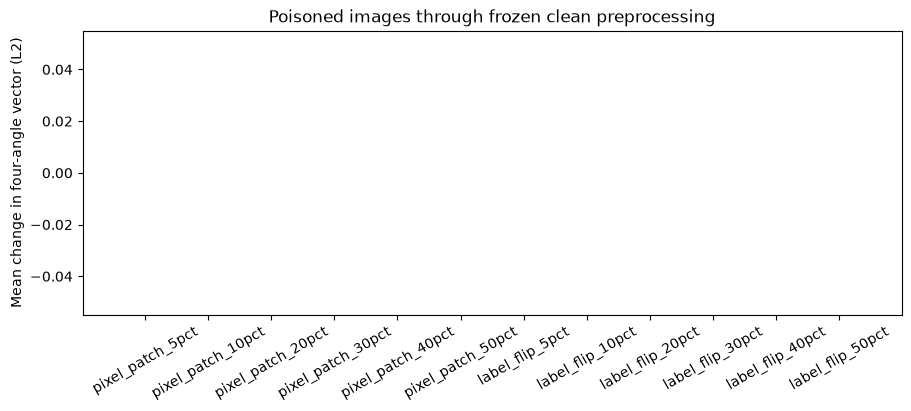

In [72]:
if not feature_effects.empty:
    figure, axis = plt.subplots(figsize=(9, 4), layout="constrained")
    axis.bar(feature_effects["condition"], feature_effects["mean_angle_l2"])
    axis.set(ylabel="Mean change in four-angle vector (L2)",
             title="Poisoned images through frozen clean preprocessing")
    axis.tick_params(axis="x", labelrotation=30)
    phase1_figures["poison_feature_effect"] = figure
    display(figure)
    plt.close(figure)


### 10.4. Train or load supervised checkpoints

Each condition links the clean gold model, poisoned model, and two matched retained-data references. The clean control aliases its poisoned role to the clean model. Reference fits with identical retained IDs are reused, including across pixel-patch rates. Classical models are also fitted on each original model's four features.

This loop can take substantially longer than the one-gold pilot. It saves progress after every completed quantum update. With `FORCE_RETRAIN=False`, rerunning loads completed models and resumes each interrupted model from its own checkpoint. A new model starts from initialization; incompatible settings start a fresh run. With `FORCE_RETRAIN=True`, each distinct enabled model starts fresh once in this session.


In [73]:
def show_stage_progress(event):
    # Keep output short while showing which model is running.
    step = event.get("step")
    if step is None or step % 50 == 0:
        loss = event.get("objective", event.get("validation_loss"))
        print(event["stage"], event["model"], "step=", step, "loss=", loss)


In [74]:
if SAVED_RESULTS_ONLY:
    training_conditions = {
        name: review.condition(config, splits, include_unlearned=False)
        for name, config in condition_configs.items()
    }
    print("Loaded supervised checkpoints for", len(training_conditions), "selected-fold conditions.")
else:
    training_conditions = {}
    for name, experiment_config in condition_configs.items():
        print("Condition:", name)
        training_conditions[name] = train_condition(
            experiment_config, splits, gold_run=gold_reference_run,
            allow_training=RUN_POISONED_TRAINING, checkpoints=checkpoints,
            root=PROJECT_ROOT, callback=show_stage_progress,
        )


Loaded supervised checkpoints for 13 selected-fold conditions.


### 10.5. Inspect clean-test performance before unlearning

All rows below use the same selected test fold. The Wilson intervals describe finite-test-sample uncertainty for accuracy under a binomial approximation; they are not variability across training seeds. Retained accuracy uses true digits 0/1 with the ordinary three-class prediction rule.

The retained-data references intentionally exclude the forget records. Their all-class accuracy is not a target to maximize after forgetting. Inspect retained accuracy and agreement with those references separately.


In [75]:
training_tables = phase1_tables(training_conditions)
training_scores = training_tables["metrics"]
if not training_scores.empty:
    columns = ["condition", "model", "n_samples", "accuracy", "accuracy_ci95_low",
               "accuracy_ci95_high", "retained_accuracy", "forget_recall", "forget_confidence"]
    display(training_scores.loc[training_scores["model"].isin(
        ["poisoned", "poisoned_logistic", "poisoned_linear_svm", "poisoned_rbf_svm"]), columns].round(4))
else:
    print("No matching supervised results yet. Enable training or select saved checkpoints.")


,condition,model,n_samples,accuracy,accuracy_ci95_low,accuracy_ci95_high,retained_accuracy,forget_recall,forget_confidence
5,clean,poisoned_linear_svm,84,0.9405,0.8681,0.9743,0.9643,0.8929,0.8105
6,clean,poisoned_logistic,84,0.9167,0.8378,0.9590,0.9643,0.8214,0.7902
8,clean,poisoned,84,0.9167,0.8378,0.9590,0.9643,0.8214,0.3975
9,clean,poisoned_rbf_svm,84,0.9405,0.8681,0.9743,0.9821,0.8571,0.7860
17,pixel_patch_5pct,poisoned_linear_svm,84,0.9405,0.8681,0.9743,0.9643,0.8929,0.8106
18,pixel_patch_5pct,poisoned_logistic,84,0.9167,0.8378,0.9590,0.9643,0.8214,0.7901
20,pixel_patch_5pct,poisoned,84,0.9167,0.8378,0.9590,0.9643,0.8214,0.3973
21,pixel_patch_5pct,poisoned_rbf_svm,84,0.9405,0.8681,0.9743,0.9821,0.8571,0.7860
29,pixel_patch_10pct,poisoned_linear_svm,84,0.9286,0.8528,0.9669,0.9643,0.8571,0.7843
30,pixel_patch_10pct,poisoned_logistic,84,0.9167,0.8378,0.9590,0.9643,0.8214,0.7895


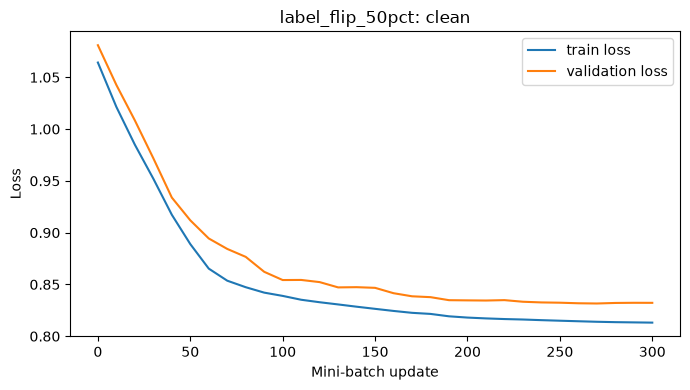

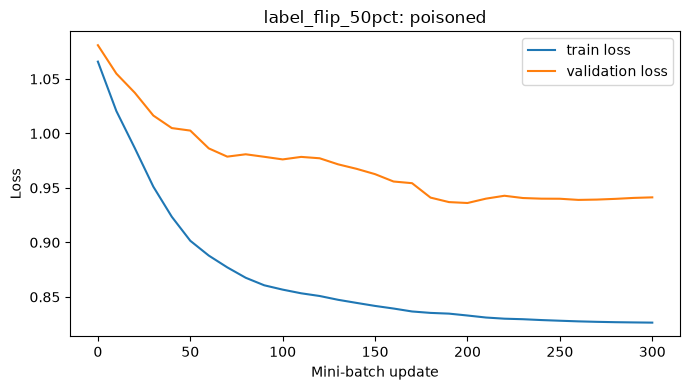

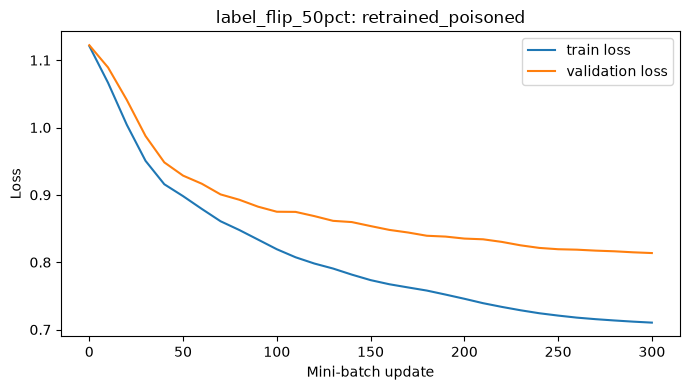

In [76]:
inspected_training = training_conditions[INSPECT_CONDITION]
for role in ("clean", "poisoned", "retrained_poisoned"):
    run = inspected_training["models"].get(role)
    if run is None:
        continue
    figure = plot_training_history(run["history"], title=f"{INSPECT_CONDITION}: {role}")
    phase1_figures[f"{INSPECT_CONDITION}_{role}_training"] = figure
    display(figure)
    plt.close(figure)


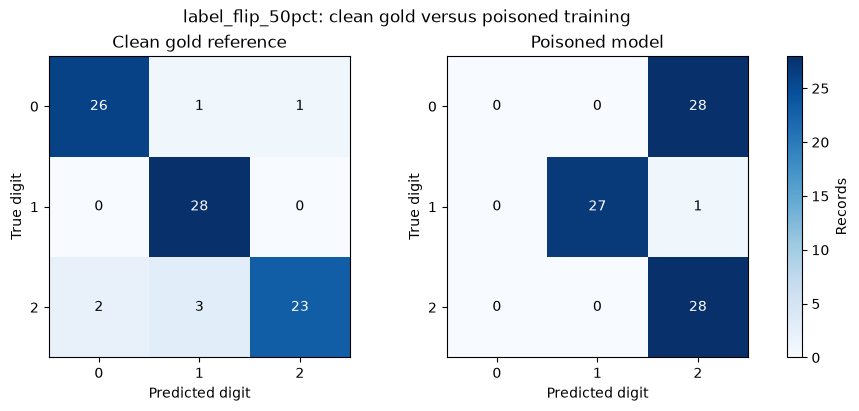

In [77]:
clean_model = inspected_training["models"].get("clean")
poisoned_model = inspected_training["models"].get("poisoned")
if clean_model is not None and poisoned_model is not None:
    figure = plot_confusion_comparison(
        clean_model["metrics"]["models"]["model"]["confusion_matrix"],
        poisoned_model["metrics"]["models"]["model"]["confusion_matrix"],
        title=f"{INSPECT_CONDITION}: clean gold versus poisoned training",
    )
    figure.axes[0].set_title("Clean gold reference")
    figure.axes[1].set_title("Poisoned model")
    phase1_figures[f"{INSPECT_CONDITION}_poisoning_confusion"] = figure
    display(figure)
    plt.close(figure)


In [78]:
display(training_tables["checkpoints"])
display(training_tables["resources"])


,condition,attack,poison_rate,seed,fold,realized_training_fraction,realized_eligible_fraction,model,run_id,best_score,best_step,selection_metric
0,clean,none,0.00,6304,0,0.000000,0.000000,clean,none_p0_seed6304_fold0_516273b4737f6f29,0.831614,270,validation_loss
1,clean,none,0.00,6304,0,0.000000,0.000000,poisoned,none_p0_seed6304_fold0_516273b4737f6f29,0.831614,270,validation_loss
2,clean,none,0.00,6304,0,0.000000,0.000000,retrained_clean,none_p0_seed6304_fold0_dbd5b57c44e38aec,0.815712,150,validation_loss
3,clean,none,0.00,6304,0,0.000000,0.000000,retrained_poisoned,none_p0_seed6304_fold0_dbd5b57c44e38aec,0.815712,150,validation_loss
4,pixel_patch_5pct,pixel_patch,0.05,6304,0,0.014925,0.044944,clean,none_p0_seed6304_fold0_516273b4737f6f29,0.831614,270,validation_loss
5,pixel_patch_5pct,pixel_patch,0.05,6304,0,0.014925,0.044944,poisoned,none_p0_seed6304_fold0_88907c37c4fd1e4c,0.831174,270,validation_loss
6,pixel_patch_5pct,pixel_patch,0.05,6304,0,0.014925,0.044944,retrained_clean,none_p0_seed6304_fold0_dbd5b57c44e38aec,0.815712,150,validation_loss
7,pixel_patch_5pct,pixel_patch,0.05,6304,0,0.014925,0.044944,retrained_poisoned,none_p0_seed6304_fold0_dbd5b57c44e38aec,0.815712,150,validation_loss
8,pixel_patch_10pct,pixel_patch,0.10,6304,0,0.029851,0.089888,clean,none_p0_seed6304_fold0_516273b4737f6f29,0.831614,270,validation_loss
9,pixel_patch_10pct,pixel_patch,0.10,6304,0,0.029851,0.089888,poisoned,none_p0_seed6304_fold0_a6bdf8b74e16dc65,0.830432,270,validation_loss


,run_id,first_role,actual_device,training_seconds,compiled_depth,two_qubit_gates,imported_from,circuit_evaluations,jobs,shots
0,none_p0_seed6304_fold0_516273b4737f6f29,clean,GPU,485.928868,66,48,none_p0_seed6304_fold0_69a3d2f1241a062b,445500,3725,0
1,none_p0_seed6304_fold0_dbd5b57c44e38aec,retrained_clean,GPU,469.111572,66,48,NaN,442028,3694,0
2,none_p0_seed6304_fold0_88907c37c4fd1e4c,poisoned,GPU,452.816149,66,48,NaN,445500,3725,0
3,none_p0_seed6304_fold0_a6bdf8b74e16dc65,poisoned,GPU,352.912221,66,48,NaN,445500,3725,0
4,none_p0_seed6304_fold0_f329aea653f69fbc,poisoned,GPU,377.623780,66,48,NaN,445500,3725,0
5,none_p0_seed6304_fold0_6c5813278f2ab601,poisoned,GPU,450.671237,66,48,NaN,445500,3725,0
6,none_p0_seed6304_fold0_d7b5ba41ec6a555b,poisoned,GPU,430.347006,66,48,NaN,445500,3725,0
7,none_p0_seed6304_fold0_b8bbf605b91b5dae,poisoned,GPU,461.073392,66,48,NaN,445500,3725,0
8,none_p0_seed6304_fold0_2b8e1a045c21c59b,poisoned,GPU,485.244862,66,48,NaN,445500,3725,0
9,none_p0_seed6304_fold0_7544900defdb2869,retrained_poisoned,GPU,353.757662,66,48,NaN,441904,3694,0


**Interpretation:** compare poisoned models with the clean gold model before attributing damage to unlearning. Inspect digit-0 and digit-2 recall for the 0-to-2 label attack. Small realized poison counts and 28 test records per class limit conclusions. Imported gold resources describe its original run, and shared model IDs must be counted once.


## 11. Guided and uniform class unlearning
### 11.1. Define fixed targets and anchors

Each method starts from the same original model checkpoint. It does not start from another unlearning method's weights. Calibration and anchor records come only from the training partition.

The guided target averages the original model's calibration predictions, raises the retained probabilities to `beta`, sets the digit-2 component to zero, and normalizes. The uniform target is `(0.5, 0.5, 0)`. Anchor targets are the original model's full predicted distributions, not clean ground-truth labels.

We minimize forget cross-entropy + `alpha` times anchor cross-entropy + `regularization` times squared parameter distance. The zero target component does not imply that this bounded-logit circuit can output exactly zero probability.


In [79]:
display(pd.Series(asdict(unlearning_config)).drop("training").to_frame("Setting"))
print("Every method restarts from its parent checkpoint; seed streams derive from", SEED)


,Setting
forget_class,2
forget_definition,observed
alpha,1.0
regularization,0.01
beta,1.0
anchor_fraction,0.25
calibration_size,32
methods,"(guided, uniform)"


Every method restarts from its parent checkpoint; seed streams derive from 6304


### 11.2. Run or load unlearning stages

Clean and poisoned cases each receive guided and uniform unlearning. Their teacher predictions are derived from their own original models. Every completed method is saved separately with fixed targets, calibration/anchor/forget IDs, original weights, and selected weights.

The saved before/after predictions use the clean held-out test fold. Unlearning checkpoint selection uses the training objective only.


In [80]:
if SAVED_RESULTS_ONLY:
    phase1_results = {name: review.condition(config, splits)
                      for name, config in condition_configs.items()}
    print("Loaded guided/uniform checkpoints; no optimization performed.")
else:
    phase1_results = {}
    for name, training_condition in training_conditions.items():
        print("Unlearning condition:", name)
        phase1_results[name] = unlearn_condition(
            training_condition, splits, allow_execution=RUN_UNLEARNING,
            checkpoints=checkpoints, root=PROJECT_ROOT, callback=show_stage_progress,
        )
phase1_summary = phase1_tables(phase1_results)


Loaded guided/uniform checkpoints; no optimization performed.


### 11.3. Inspect targets and teacher quality

Compare guided targets between clean and poisoned models. A change may show how poisoning changes the distribution-guided signal. Anchor accuracy is measured against original and observed labels for auditing; neither value replaces the cached teacher probabilities in the objective.


,condition,attack,poison_rate,seed,fold,realized_training_fraction,realized_eligible_fraction,model,target_0,target_1,target_2,anchor_accuracy_observed_labels,anchor_accuracy_original_labels,n_anchors,n_calibration,n_forget
0,clean,none,0.00,6304,0,0.0000,0.0000,clean_guided,0.5132,0.4868,0.0,0.9348,0.9348,46,32,89
1,clean,none,0.00,6304,0,0.0000,0.0000,clean_uniform,0.5000,0.5000,0.0,0.9348,0.9348,46,32,89
2,clean,none,0.00,6304,0,0.0000,0.0000,poisoned_guided,0.5132,0.4868,0.0,0.9348,0.9348,46,32,89
3,clean,none,0.00,6304,0,0.0000,0.0000,poisoned_uniform,0.5000,0.5000,0.0,0.9348,0.9348,46,32,89
4,pixel_patch_5pct,pixel_patch,0.05,6304,0,0.0149,0.0449,clean_guided,0.5132,0.4868,0.0,0.9348,0.9348,46,32,89
5,pixel_patch_5pct,pixel_patch,0.05,6304,0,0.0149,0.0449,clean_uniform,0.5000,0.5000,0.0,0.9348,0.9348,46,32,89
6,pixel_patch_5pct,pixel_patch,0.05,6304,0,0.0149,0.0449,poisoned_guided,0.5134,0.4866,0.0,0.9348,0.9348,46,32,89
7,pixel_patch_5pct,pixel_patch,0.05,6304,0,0.0149,0.0449,poisoned_uniform,0.5000,0.5000,0.0,0.9348,0.9348,46,32,89
8,pixel_patch_10pct,pixel_patch,0.10,6304,0,0.0299,0.0899,clean_guided,0.5132,0.4868,0.0,0.9348,0.9348,46,32,89
9,pixel_patch_10pct,pixel_patch,0.10,6304,0,0.0299,0.0899,clean_uniform,0.5000,0.5000,0.0,0.9348,0.9348,46,32,89


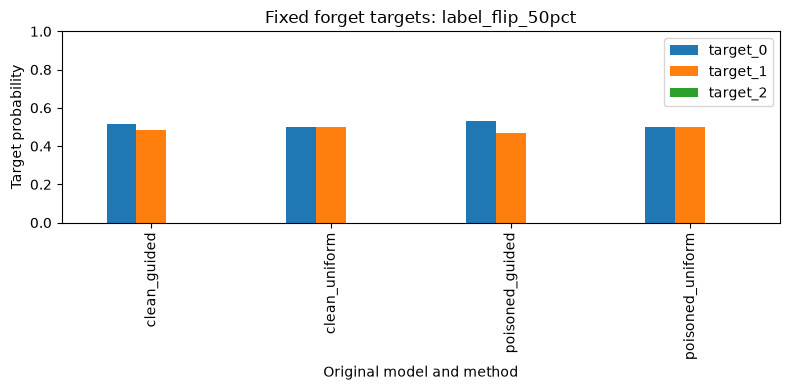

In [81]:
display(phase1_summary["targets"].round(4))
target_table = phase1_summary["targets"]
if not target_table.empty:
    selected = target_table.loc[target_table["condition"] == INSPECT_CONDITION]
    if selected.empty:
        print("No target results yet for the selected inspection condition.")
    else:
        axis = selected.set_index("model")[["target_0", "target_1", "target_2"]].plot.bar(
            figsize=(8, 4), ylim=(0, 1), title=f"Fixed forget targets: {INSPECT_CONDITION}",
        )
        axis.set(ylabel="Target probability", xlabel="Original model and method")
        figure = axis.figure
        figure.tight_layout()
        phase1_figures[f"{INSPECT_CONDITION}_targets"] = figure
        display(figure)
        plt.close(figure)


### 11.4. Compare retention, forgetting, and matched retraining

The KL direction is **retained-data reference || candidate** on clean retained test examples. Conditional KL renormalizes over classes 0/1; full KL and forgotten-class mass expose effects that conditioning can hide. Low KL is evidence of predictive agreement on these examples, not a certificate of deletion.


In [82]:
phase1_metrics = phase1_summary["metrics"]
if not phase1_metrics.empty:
    selected = phase1_metrics.loc[phase1_metrics["condition"] == INSPECT_CONDITION]
    display(selected[["model", "accuracy", "retained_accuracy", "forget_recall",
                      "forget_confidence", "forgotten_mass_on_retained"]].round(4))
display(phase1_summary["retraining"].round(4))
display(phase1_summary["per_class"].query("condition == @INSPECT_CONDITION")
        if not phase1_summary["per_class"].empty else phase1_summary["per_class"])


,model,accuracy,retained_accuracy,forget_recall,forget_confidence,forgotten_mass_on_retained
192,clean_linear_svm,0.9405,0.9643,0.8929,0.8105,0.0789
193,clean_logistic,0.9167,0.9643,0.8214,0.7902,0.0706
194,clean_majority,0.3333,0.5000,0.0000,0.0000,0.0000
195,clean,0.9167,0.9643,0.8214,0.3975,0.2791
196,clean_rbf_svm,0.9405,0.9821,0.8571,0.7860,0.0554
197,poisoned_linear_svm,0.6548,0.4821,1.0000,0.7796,0.3697
198,poisoned_logistic,0.7143,0.5893,0.9643,0.8415,0.3254
199,poisoned_majority,0.3333,0.0000,1.0000,1.0000,1.0000
200,poisoned,0.6548,0.4821,1.0000,0.4804,0.3982
201,poisoned_rbf_svm,0.7262,0.6071,0.9643,0.7962,0.3726


,condition,attack,poison_rate,seed,fold,realized_training_fraction,realized_eligible_fraction,model,kl_direction,evaluation_subset,full_kl_mean,conditional_kl_mean,conditional_kl_median,conditional_kl_max,reference_forgotten_mass,candidate_forgotten_mass
0,clean,none,0.0,6304,0,0.0000,0.0,clean,reference || candidate,clean retained test,0.0135,0.0070,0.0029,0.0310,0.2590,0.2791
1,clean,none,0.0,6304,0,0.0000,0.0,poisoned,reference || candidate,clean retained test,0.0135,0.0070,0.0029,0.0310,0.2590,0.2791
2,clean,none,0.0,6304,0,0.0000,0.0,clean_guided,reference || candidate,clean retained test,0.0219,0.0101,0.0060,0.0391,0.2590,0.3006
3,clean,none,0.0,6304,0,0.0000,0.0,clean_uniform,reference || candidate,clean retained test,0.0227,0.0116,0.0066,0.0501,0.2590,0.2993
4,clean,none,0.0,6304,0,0.0000,0.0,poisoned_guided,reference || candidate,clean retained test,0.0219,0.0101,0.0060,0.0391,0.2590,0.3006
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
73,label_flip_50pct,label_flip,0.5,6304,0,0.1679,0.5,poisoned,reference || candidate,clean retained test,0.0575,0.0090,0.0051,0.0419,0.2644,0.3982
74,label_flip_50pct,label_flip,0.5,6304,0,0.1679,0.5,clean_guided,reference || candidate,clean retained test,0.0219,0.0101,0.0060,0.0391,0.2590,0.3006
75,label_flip_50pct,label_flip,0.5,6304,0,0.1679,0.5,clean_uniform,reference || candidate,clean retained test,0.0227,0.0116,0.0066,0.0501,0.2590,0.2993
76,label_flip_50pct,label_flip,0.5,6304,0,0.1679,0.5,poisoned_guided,reference || candidate,clean retained test,0.0351,0.0148,0.0095,0.0768,0.2644,0.3151


,condition,attack,poison_rate,seed,fold,realized_training_fraction,realized_eligible_fraction,model,digit,n_test,correct,recall
576,label_flip_50pct,label_flip,0.5,6304,0,0.16791,0.5,clean_linear_svm,0,28,27,0.964286
577,label_flip_50pct,label_flip,0.5,6304,0,0.16791,0.5,clean_linear_svm,1,28,27,0.964286
578,label_flip_50pct,label_flip,0.5,6304,0,0.16791,0.5,clean_linear_svm,2,28,25,0.892857
579,label_flip_50pct,label_flip,0.5,6304,0,0.16791,0.5,clean_logistic,0,28,27,0.964286
580,label_flip_50pct,label_flip,0.5,6304,0,0.16791,0.5,clean_logistic,1,28,27,0.964286
581,label_flip_50pct,label_flip,0.5,6304,0,0.16791,0.5,clean_logistic,2,28,23,0.821429
582,label_flip_50pct,label_flip,0.5,6304,0,0.16791,0.5,clean_majority,0,28,28,1.000000
583,label_flip_50pct,label_flip,0.5,6304,0,0.16791,0.5,clean_majority,1,28,0,0.000000
584,label_flip_50pct,label_flip,0.5,6304,0,0.16791,0.5,clean_majority,2,28,0,0.000000
585,label_flip_50pct,label_flip,0.5,6304,0,0.16791,0.5,clean,0,28,26,0.928571


### 11.5. Inspect optimization and prediction changes

These figures show the selected condition in detail. Other conditions remain in the tables and rate curves. Compare the loss trajectory with the saved selected checkpoint; the final iteration need not be the selected model.


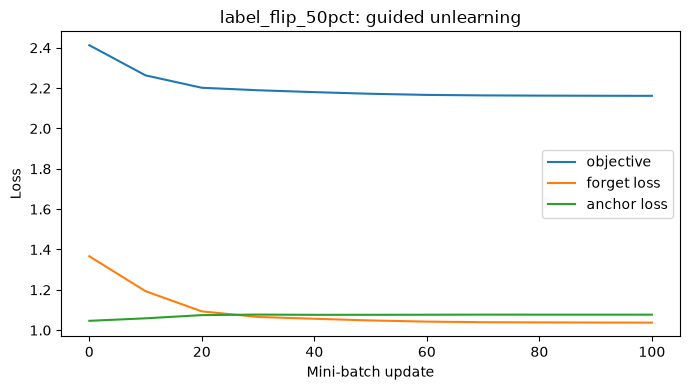

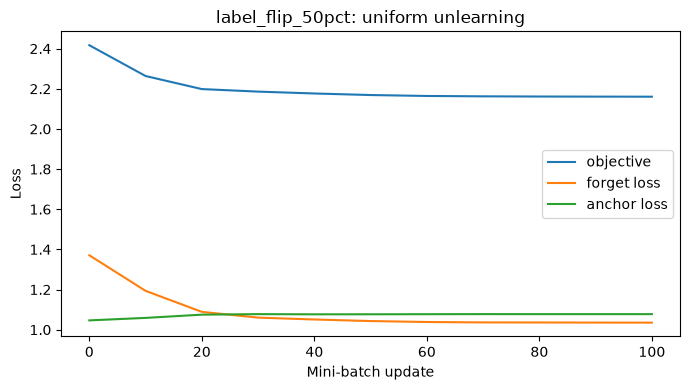

In [83]:
inspected_result = phase1_results[INSPECT_CONDITION]
for method in unlearning_config.methods:
    run = inspected_result["unlearned"].get(f"poisoned_{method}")
    if run is None:
        continue
    figure = plot_training_history(
        run["history"], columns=["objective", "forget_loss", "anchor_loss"],
        title=f"{INSPECT_CONDITION}: {method} unlearning",
    )
    phase1_figures[f"{INSPECT_CONDITION}_{method}_objective"] = figure
    display(figure)
    plt.close(figure)


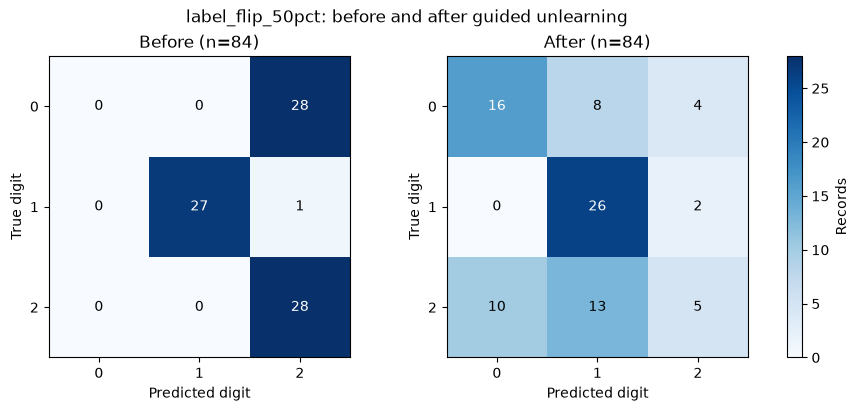

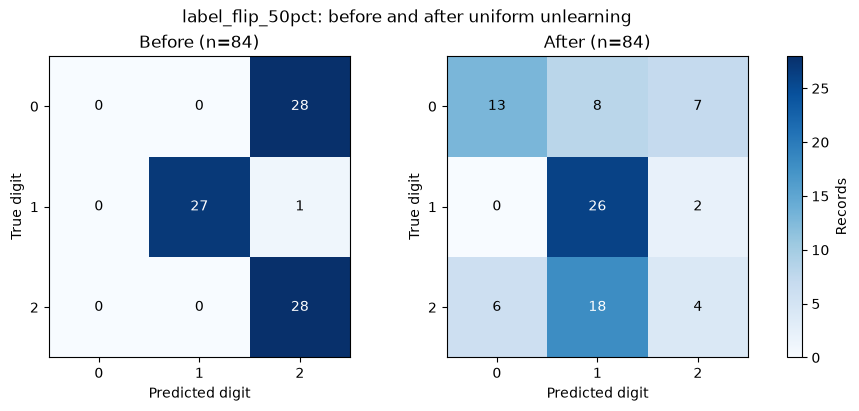

In [84]:
parent = inspected_result["models"].get("poisoned")
for method in unlearning_config.methods:
    run = inspected_result["unlearned"].get(f"poisoned_{method}")
    if parent is None or run is None:
        continue
    figure = plot_confusion_comparison(
        parent["metrics"]["models"]["model"]["confusion_matrix"],
        run["metrics"]["models"]["model"]["confusion_matrix"],
        title=f"{INSPECT_CONDITION}: before and after {method} unlearning",
    )
    phase1_figures[f"{INSPECT_CONDITION}_{method}_confusion"] = figure
    display(figure)
    plt.close(figure)


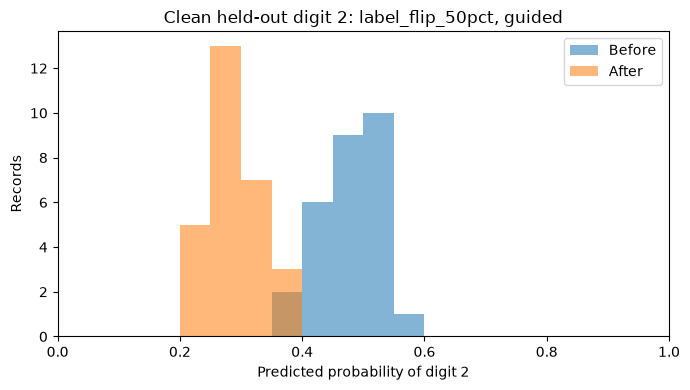

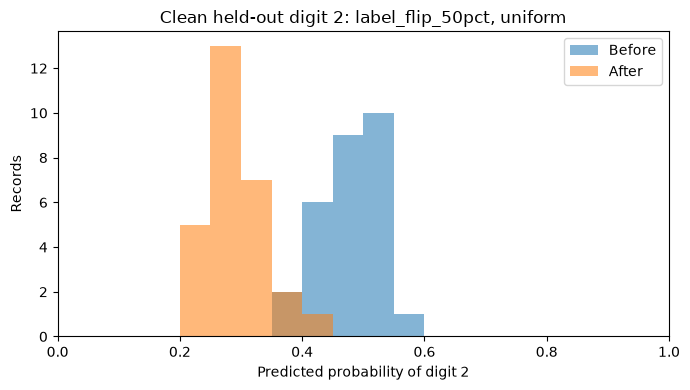

In [85]:
for method in unlearning_config.methods:
    run = inspected_result["unlearned"].get(f"poisoned_{method}")
    if parent is None or run is None:
        continue
    figure = plot_forget_confidence(
        splits.test.labels, parent["predictions"]["model__test"],
        run["predictions"]["model__test"], forget_class=2,
    )
    figure.axes[0].set_title(f"Clean held-out digit 2: {INSPECT_CONDITION}, {method}")
    phase1_figures[f"{INSPECT_CONDITION}_{method}_confidence"] = figure
    display(figure)
    plt.close(figure)


### 11.6. Separate poisoning damage from unlearning changes

`poisoning_damage_before` is poisoned minus clean before unlearning. `additional_change_under_poisoning` is the poisoned before/after change minus the clean before/after change. Negative retained-accuracy changes indicate lost utility; negative forget-confidence changes indicate suppression.

Under observed-label forgetting, label flips also change which training records are removed. Report this difference explicitly: the clean and poisoned forget sets are not identical. The matched retraining reference for each case excludes its own exact forget IDs.


In [86]:
display(phase1_summary["changes"].round(4))
display(phase1_summary["effects"].round(4))


,condition,attack,poison_rate,seed,fold,realized_training_fraction,realized_eligible_fraction,model,forget_confidence_delta,forget_confidence_reduction,forget_recall_delta,retained_accuracy_delta
0,clean,none,0.00,6304,0,0.0000,0.0000,clean_guided,-0.1229,0.1229,-0.8214,-0.0357
1,clean,none,0.00,6304,0,0.0000,0.0000,clean_uniform,-0.1246,0.1246,-0.8214,-0.0179
2,clean,none,0.00,6304,0,0.0000,0.0000,poisoned_guided,-0.1229,0.1229,-0.8214,-0.0357
3,clean,none,0.00,6304,0,0.0000,0.0000,poisoned_uniform,-0.1246,0.1246,-0.8214,-0.0179
4,pixel_patch_5pct,pixel_patch,0.05,6304,0,0.0149,0.0449,clean_guided,-0.1229,0.1229,-0.8214,-0.0357
5,pixel_patch_5pct,pixel_patch,0.05,6304,0,0.0149,0.0449,clean_uniform,-0.1246,0.1246,-0.8214,-0.0179
6,pixel_patch_5pct,pixel_patch,0.05,6304,0,0.0149,0.0449,poisoned_guided,-0.1225,0.1225,-0.8214,-0.0357
7,pixel_patch_5pct,pixel_patch,0.05,6304,0,0.0149,0.0449,poisoned_uniform,-0.1243,0.1243,-0.8214,-0.0179
8,pixel_patch_10pct,pixel_patch,0.10,6304,0,0.0299,0.0899,clean_guided,-0.1229,0.1229,-0.8214,-0.0357
9,pixel_patch_10pct,pixel_patch,0.10,6304,0,0.0299,0.0899,clean_uniform,-0.1246,0.1246,-0.8214,-0.0179


,condition,method,metric,attack,poison_rate,seed,fold,poisoning_damage_before,clean_unlearning_change,poisoned_unlearning_change,additional_change_under_poisoning
0,clean,guided,retained_accuracy,none,0.0,6304,0,0.0000,-0.0357,-0.0357,0.0000
1,clean,guided,forget_confidence,none,0.0,6304,0,0.0000,-0.1229,-0.1229,0.0000
2,clean,guided,forget_recall,none,0.0,6304,0,0.0000,-0.8214,-0.8214,0.0000
3,clean,uniform,retained_accuracy,none,0.0,6304,0,0.0000,-0.0179,-0.0179,0.0000
4,clean,uniform,forget_confidence,none,0.0,6304,0,0.0000,-0.1246,-0.1246,0.0000
...,...,...,...,...,...,...,...,...,...,...,...
73,label_flip_50pct,guided,forget_confidence,label_flip,0.5,6304,0,0.0829,-0.1229,-0.1907,-0.0678
74,label_flip_50pct,guided,forget_recall,label_flip,0.5,6304,0,0.1786,-0.8214,-0.8214,0.0000
75,label_flip_50pct,uniform,retained_accuracy,label_flip,0.5,6304,0,-0.4821,-0.0179,0.2143,0.2321
76,label_flip_50pct,uniform,forget_confidence,label_flip,0.5,6304,0,0.0829,-0.1246,-0.1919,-0.0674


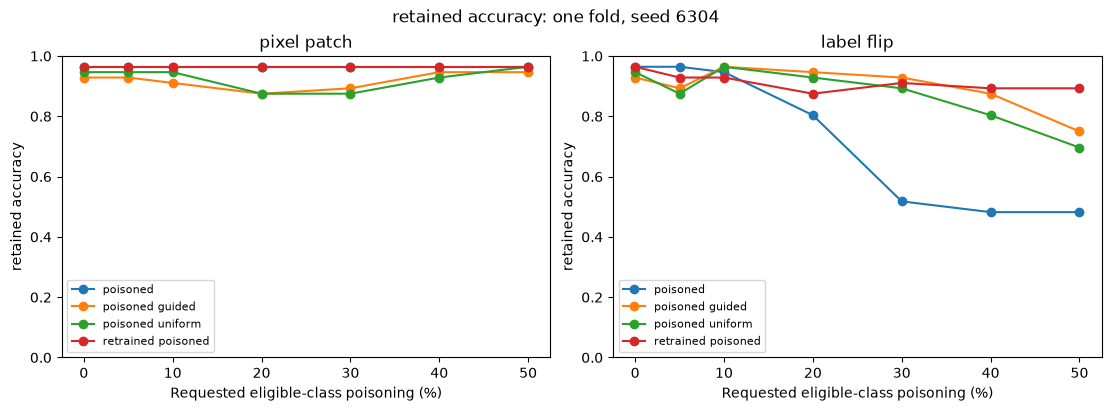

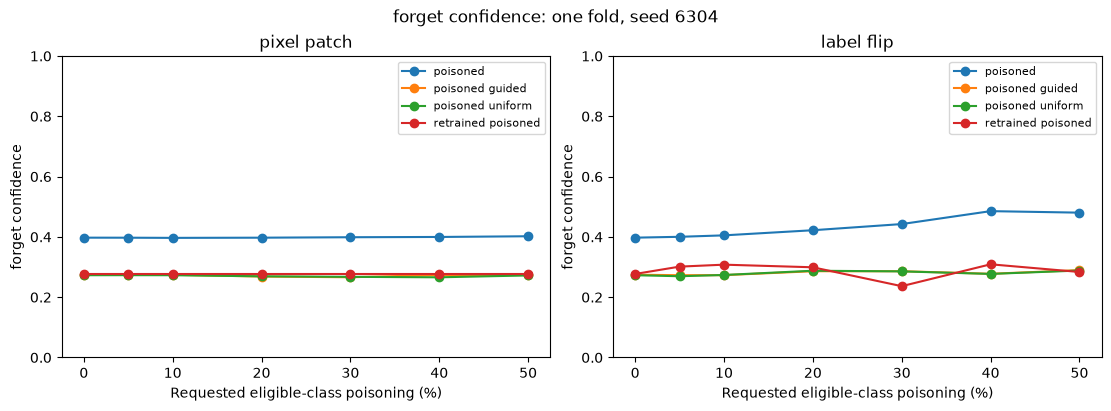

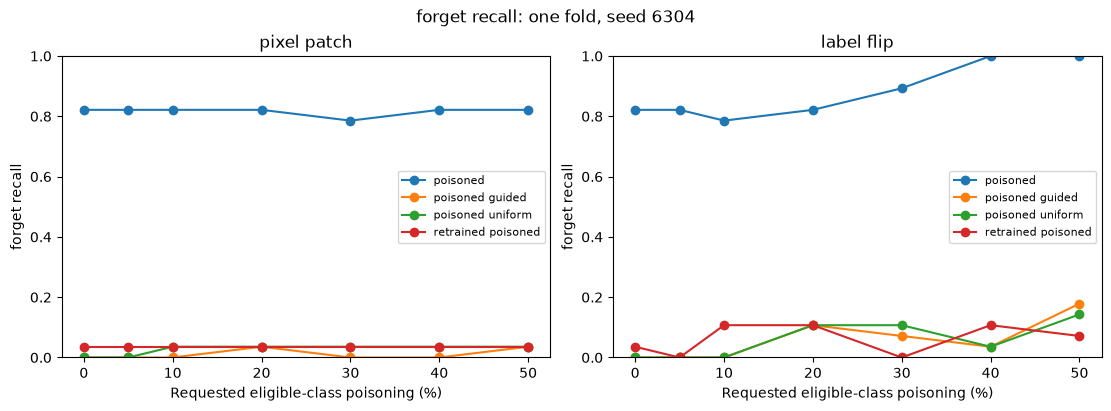

In [87]:
if not phase1_metrics.empty:
    for metric in ("retained_accuracy", "forget_confidence", "forget_recall"):
        figure = plot_condition_curves(phase1_metrics, metric)
        phase1_figures[f"poisoning_response_{metric}"] = figure
        display(figure)
        plt.close(figure)


**Interpretation:** suppression of digit-2 predictions is intentional in class unlearning. It does not mean that poisoned zeros have been repaired or that only poisoned records were forgotten. Examine retained performance, target changes, exact record membership, and agreement with retraining together. A flat poisoning curve may indicate robustness, an ineffective attack after preprocessing, limited sample size, or insufficient optimization.


## 12. All-fold evaluation and additional simulator experiments
### 12.1. Complete the paired conditions on all five folds

This is part of the main experiment. Each fold fits its own preprocessing and models; validation and test records stay clean. The selected fold reuses Sections 10-11. Checkpoints allow the loop to resume after an interruption. There are 13 conditions per fold, including the clean control, with identical clean/reference fitting problems shared where appropriate.

The summaries below report per-fold scores and fold means with descriptive standard deviations. Check digits 0 and 1 separately, class-2 suppression, and agreement with matched retraining. Paired poisoning effects are calculated within each fold before aggregation. Fold SD measures split variation with overlapping training sets; it is not uncertainty across independent seeds or a confidence interval. We still use only seed 6304.


In [88]:
if SAVED_RESULTS_ONLY:
    STUDY_FOLDS = tuple(range(data_config.n_folds))
    fold_conditions = {}
    for fold_index in STUDY_FOLDS:
        for name, config in condition_configs.items():
            current_config = replace(config, data=replace(data_config, fold=fold_index))
            fold_conditions[f"fold_{fold_index}_{name}"] = review.condition(current_config, folds[fold_index])
    print("Loaded", len(fold_conditions), "conditions across", len(STUDY_FOLDS), "folds.")
else:
    STUDY_FOLDS = tuple(range(data_config.n_folds))
    fold_conditions = {
        f"fold_{data_config.fold}_{name}": result for name, result in phase1_results.items()
    }
    if RUN_FOLD_STUDY:
        for fold_index in STUDY_FOLDS:
            if fold_index == data_config.fold:
                continue
            for name, current_config in condition_configs.items():
                current_config = replace(current_config, data=replace(data_config, fold=fold_index))
                trained = train_condition(current_config, folds[fold_index], allow_training=RUN_POISONED_TRAINING,
                                          checkpoints=checkpoints, root=PROJECT_ROOT, callback=show_stage_progress)
                fold_conditions[f"fold_{fold_index}_{name}"] = unlearn_condition(
                    trained, folds[fold_index], allow_execution=RUN_UNLEARNING,
                    checkpoints=checkpoints, root=PROJECT_ROOT, callback=show_stage_progress,
                )


Loaded 65 conditions across 5 folds.


In [89]:
fold_tables = phase1_tables(fold_conditions)
fold_aggregates = fold_summaries(fold_tables, expected_folds=STUDY_FOLDS)
fold_summary = fold_aggregates["metrics"]
fold_effect_summary = fold_aggregates["effects"]
quantum_roles = ("poisoned", "poisoned_guided", "poisoned_uniform", "retrained_poisoned")
if not fold_summary.empty:
    display(fold_summary.loc[fold_summary["model"].isin(quantum_roles)].round(4))
    print("Incomplete metric rows:", int((~fold_summary["complete_folds"]).sum()))
print("Seed count: 1. Fold SD is descriptive; it is undefined when only one fold is available.")


,seed,attack,poison_rate,model,metric,mean,fold_sd,n_folds,expected_folds,complete_folds
28,6304,label_flip,0.05,poisoned,accuracy,0.8929,0.0453,5,5,True
29,6304,label_flip,0.05,poisoned,retained_accuracy,0.9250,0.0407,5,5,True
30,6304,label_flip,0.05,poisoned,forget_recall,0.8286,0.0687,5,5,True
31,6304,label_flip,0.05,poisoned,forget_confidence,0.4086,0.0213,5,5,True
32,6304,label_flip,0.05,poisoned_guided,accuracy,0.5833,0.0607,5,5,True
...,...,...,...,...,...,...,...,...,...,...
1595,6304,pixel_patch,0.40,retrained_poisoned,recall_digit_2,0.0214,0.0196,5,5,True
1603,6304,pixel_patch,0.50,poisoned,recall_digit_2,0.7929,0.0687,5,5,True
1604,6304,pixel_patch,0.50,poisoned_guided,recall_digit_2,0.0071,0.0160,5,5,True
1609,6304,pixel_patch,0.50,poisoned_uniform,recall_digit_2,0.0071,0.0160,5,5,True


Incomplete metric rows: 0
Seed count: 1. Fold SD is descriptive; it is undefined when only one fold is available.


### 12.1.1. Compare classes and methods across folds

These tables retain each fold's results, including unfavorable outcomes. Use class-0 and class-1 recall to check retention separately. Lower class-2 recall/confidence measures suppression; lower KL means closer predictions to the corresponding retained-data retraining reference. Neither measure certifies removal of training information.

In [90]:
if not fold_tables["per_class"].empty:
    display(fold_tables["per_class"].loc[
        fold_tables["per_class"]["model"].isin(quantum_roles),
        ["fold", "attack", "poison_rate", "model", "digit", "n_test", "correct", "recall"],
    ].round(4))
if not fold_effect_summary.empty:
    display(fold_effect_summary.loc[
        fold_effect_summary["metric"] == "additional_change_under_poisoning"
    ].round(4))

,fold,attack,poison_rate,model,digit,n_test,correct,recall
24,0,none,0.0,poisoned,0,28,26,0.9286
25,0,none,0.0,poisoned,1,28,28,1.0000
26,0,none,0.0,poisoned,2,28,23,0.8214
33,0,none,0.0,retrained_poisoned,0,28,26,0.9286
34,0,none,0.0,retrained_poisoned,1,28,28,1.0000
...,...,...,...,...,...,...,...,...
3115,4,label_flip,0.5,poisoned_guided,1,28,24,0.8571
3116,4,label_flip,0.5,poisoned_guided,2,28,0,0.0000
3117,4,label_flip,0.5,poisoned_uniform,0,28,11,0.3929
3118,4,label_flip,0.5,poisoned_uniform,1,28,24,0.8571


,seed,attack,poison_rate,method,outcome,metric,mean,fold_sd,n_folds,expected_folds,complete_folds
3,6304,label_flip,0.05,guided,forget_confidence,additional_change_under_poisoning,0.0015,0.0182,5,5,True
7,6304,label_flip,0.05,guided,forget_recall,additional_change_under_poisoning,-0.0143,0.0196,5,5,True
11,6304,label_flip,0.05,guided,retained_accuracy,additional_change_under_poisoning,-0.0179,0.0282,5,5,True
15,6304,label_flip,0.05,uniform,forget_confidence,additional_change_under_poisoning,-0.0016,0.0181,5,5,True
19,6304,label_flip,0.05,uniform,forget_recall,additional_change_under_poisoning,-0.0143,0.0196,5,5,True
...,...,...,...,...,...,...,...,...,...,...,...
295,6304,pixel_patch,0.50,guided,forget_recall,additional_change_under_poisoning,0.0286,0.0299,5,5,True
299,6304,pixel_patch,0.50,guided,retained_accuracy,additional_change_under_poisoning,-0.0179,0.0505,5,5,True
303,6304,pixel_patch,0.50,uniform,forget_confidence,additional_change_under_poisoning,-0.0051,0.0411,5,5,True
307,6304,pixel_patch,0.50,uniform,forget_recall,additional_change_under_poisoning,0.0286,0.0299,5,5,True


### 12.1.2. Inspect poisoning curves with fold variation

Points are means across the available folds and error bars are one descriptive fold SD. Check `n_folds`, `complete_folds`, and Section 14 coverage before drawing conclusions. Missing runs are not zero-valued results. The clean control is shown at 0% for both attacks. Positive additional retention change is beneficial; positive additional forget confidence/recall means weaker suppression.

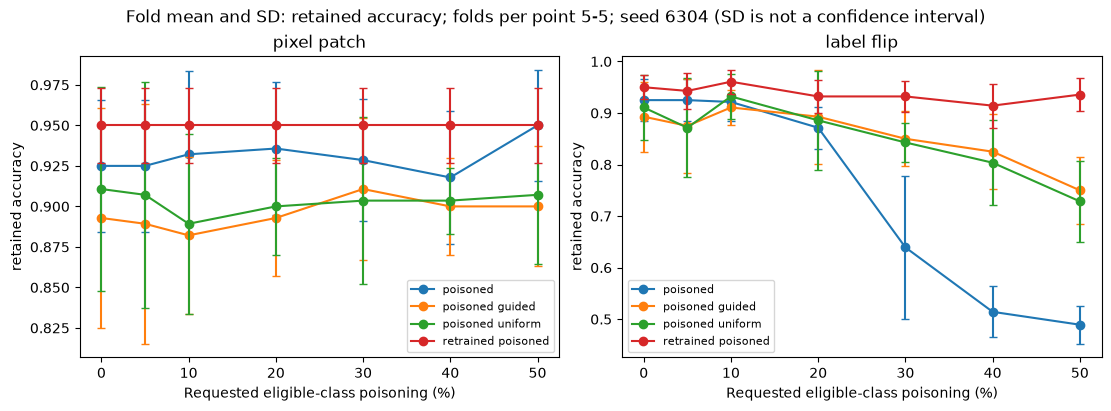

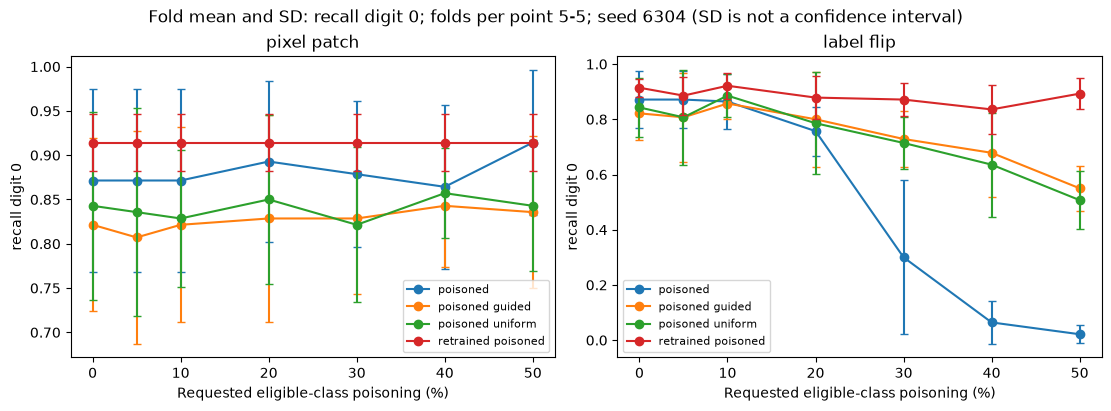

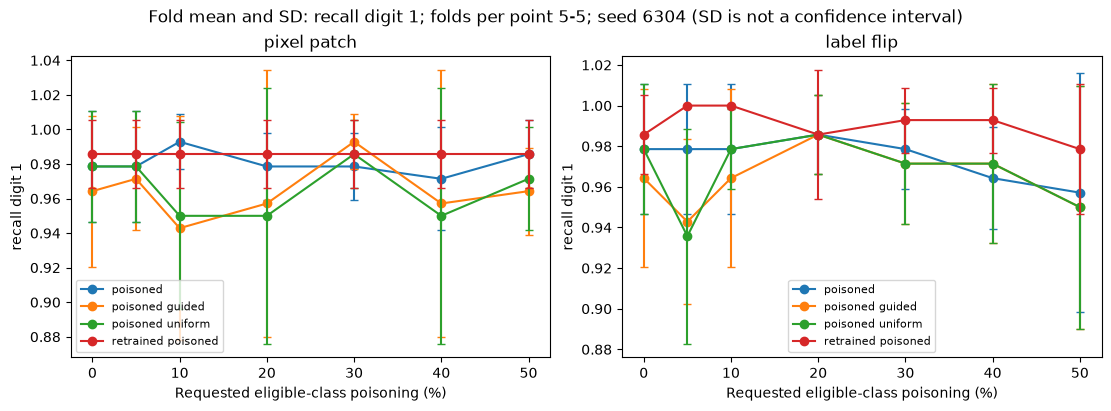

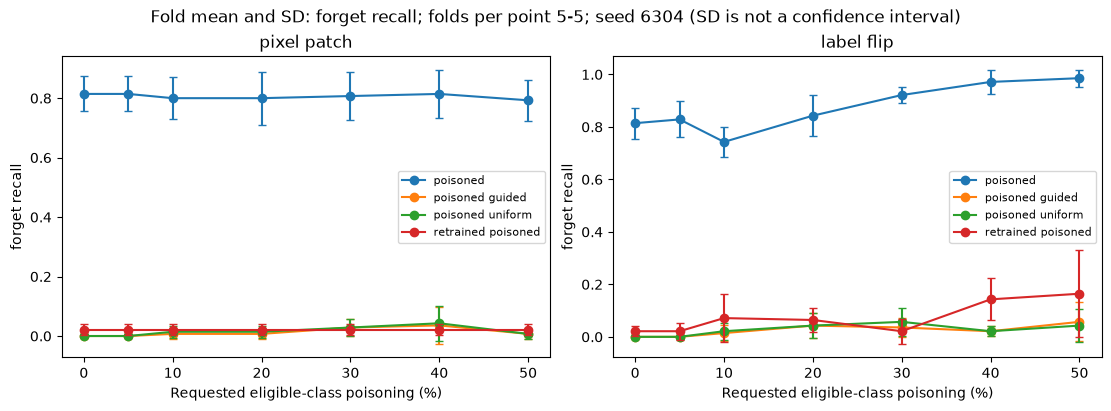

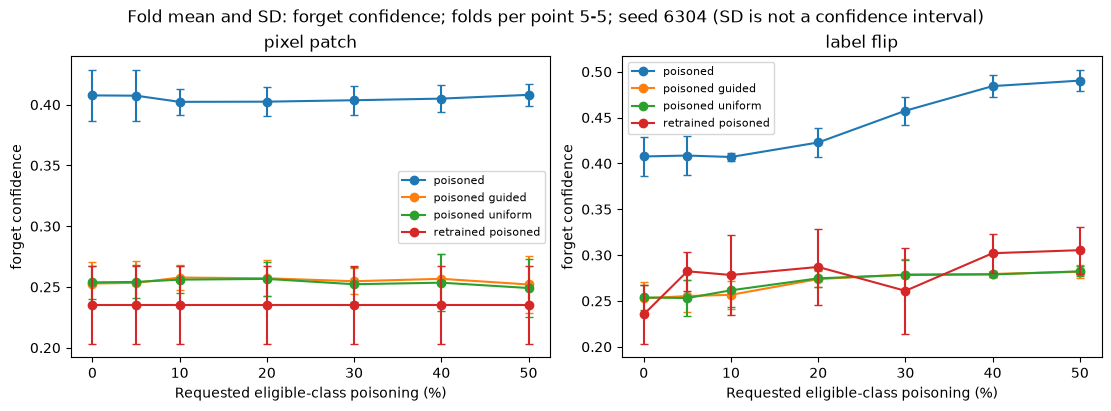

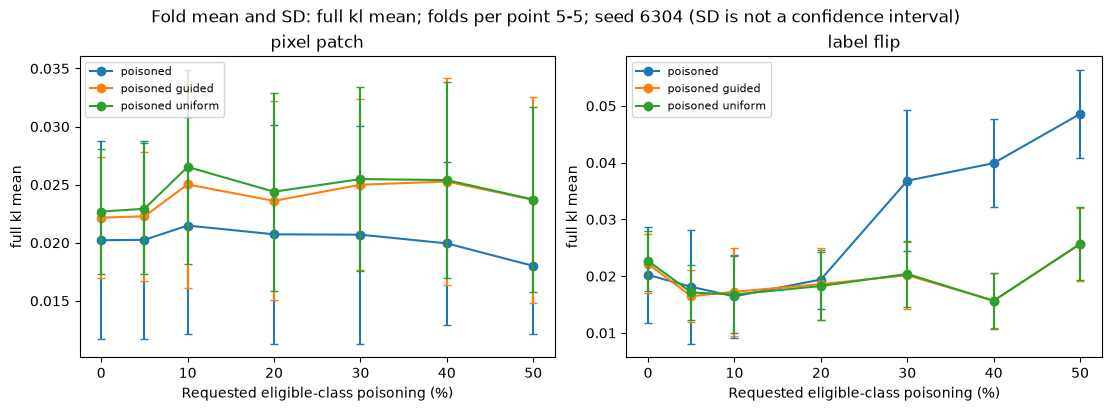

In [91]:
if not fold_summary.empty:
    for metric in ("retained_accuracy", "recall_digit_0", "recall_digit_1",
                   "forget_recall", "forget_confidence", "full_kl_mean"):
        if metric not in set(fold_summary["metric"]):
            continue
        figure = plot_fold_summary(fold_summary, metric)
        phase1_figures[f"all_folds_{metric}"] = figure
        display(figure)
        plt.close(figure)

### 12.2. Test the method's components

These optional ablations keep the selected poisoned model, record split, and seed fixed. They vary one unlearning setting at a time. The baseline remains the declared protocol; do not choose a winning setting from these test results and describe it as independently validated.


In [92]:
ablation_settings = {
    "no_anchors": replace(unlearning_config, alpha=0.0),
    "no_parameter_penalty": replace(unlearning_config, regularization=0.0),
    "beta_half": replace(unlearning_config, beta=0.5),
    "half_retained_as_anchors": replace(unlearning_config, anchor_fraction=0.5),
}
ablation_conditions = {"baseline": phase1_results[INSPECT_CONDITION]}
if RUN_ABLATIONS:
    for name, settings in ablation_settings.items():
        ablation_config = replace(condition_configs[INSPECT_CONDITION], unlearning=settings)
        ablation_conditions[name] = unlearn_condition(
            training_conditions[INSPECT_CONDITION], splits, config=ablation_config,
            allow_execution=True, checkpoints=checkpoints,
            root=PROJECT_ROOT, callback=show_stage_progress,
        )
ablation_tables = phase1_tables(ablation_conditions)


In [93]:
if not ablation_tables["metrics"].empty:
    rows = ablation_tables["metrics"]
    display(rows.loc[rows["model"].isin(["poisoned_guided", "poisoned_uniform"]),
                     ["condition", "model", "retained_accuracy", "forget_confidence", "forget_recall"]].round(4))


,condition,model,retained_accuracy,forget_confidence,forget_recall
14,baseline,poisoned_guided,0.7500,0.2898,0.1786
15,baseline,poisoned_uniform,0.6964,0.2885,0.1429


### 12.3. Optional shuffled-label control

This trains a separate model on randomly permuted clean training labels while keeping validation and test labels correct. The permutation preserves class counts and uses seed 6304. It is a negative control, not one of the poisoning conditions and not the gold reference.


In [94]:
shuffle_results = {}
if RUN_SHUFFLE_CONTROL:
    shuffle_config = replace(condition_configs["clean"], label_shuffle_control=True)
    shuffle_results["label_shuffle_control"] = train_condition(
        shuffle_config, splits, gold_run=gold_reference_run, allow_training=True,
        checkpoints=checkpoints, root=PROJECT_ROOT, callback=show_stage_progress,
    )
shuffle_tables = phase1_tables(shuffle_results)
if not shuffle_tables["metrics"].empty:
    display(shuffle_tables["metrics"].query("model == 'label_shuffle'"))


### 12.4. Evaluate fixed weights under device noise

This optional evaluation changes simulator noise without retraining. It applies single-qubit depolarizing probability `p` and two-qubit probability `2p`; readout error remains at the configured value. Every role uses the same clean test IDs and seed. These results measure sensitivity of saved weights, not noisy-training performance.


In [95]:
from src.experiments import evaluate_noise_sweep
from src.evaluation.metrics import classification_metrics

NOISE_LEVELS = (0.0, 0.001, 0.005, 0.01)
SHOT_BUDGETS = (512, 2048, 8192)
EVALUATION_ROLES = ("poisoned", "poisoned_guided", "poisoned_uniform")
evaluation_runs = {**inspected_result["models"], **inspected_result["unlearned"]}
noise_rows = []
if RUN_NOISE_SWEEP:
    for role in EVALUATION_ROLES:
        run = evaluation_runs.get(role)
        if run is None:
            continue
        model, processor, weights = restore_stage_model(run)
        frame = evaluate_noise_sweep(
            circuit_config, replace(backend_config, method="density_matrix", shots=2048),
            processor.transform(splits.test.images), splits.test.labels, weights,
            noise_levels=NOISE_LEVELS, seeds=(SEED,),
        )
        noise_rows.append(frame.assign(model=role, source_run_id=run["path"].name,
                                       shots=2048))
noise_table = pd.concat(noise_rows, ignore_index=True) if noise_rows else pd.DataFrame()
display(noise_table)


""


### 12.5. Evaluate fixed weights at different shot budgets

These are fresh evaluations of the same selected weights. Increasing shots changes sampling precision and cost; it does not train a different model. One evaluation seed provides no estimate of variation across independent seeds.


In [96]:
shot_rows = []
if RUN_SHOT_SWEEP:
    for role in EVALUATION_ROLES:
        run = evaluation_runs.get(role)
        if run is None:
            continue
        for shots in SHOT_BUDGETS:
            model, processor, weights = restore_stage_model(run, replace(backend_config, shots=shots))
            probabilities = model.predict_proba(processor.transform(splits.test.images), weights)
            metrics = classification_metrics(splits.test.labels, probabilities)
            shot_rows.append({"model": role, "shots": shots, "seed": SEED,
                              "source_run_id": run["path"].name, "actual_device": model.executor.actual_device,
                              "retained_accuracy": metrics["retained_accuracy"],
                              "forget_confidence": metrics["forget_confidence"]})
shot_table = pd.DataFrame(shot_rows)
display(shot_table)


""


In [97]:
for name, frame, x_column in (("noise", noise_table, "noise_level"),
                               ("shots", shot_table, "shots")):
    if frame.empty:
        continue
    figure, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
    for axis, metric in zip(axes, ("retained_accuracy", "forget_confidence")):
        for role, rows in frame.groupby("model"):
            rows = rows.sort_values(x_column)
            axis.plot(rows[x_column], rows[metric], "o-", label=role)
        axis.set(xlabel=x_column.replace("_", " "), ylabel=metric.replace("_", " "), ylim=(0, 1))
        axis.legend(fontsize=8)
    figure.suptitle(f"Fixed weights: {INSPECT_CONDITION}; seed {SEED}")
    phase1_figures[f"{name}_evaluation"] = figure
    display(figure)
    plt.close(figure)


## 13. Optional IBM hardware evaluation

This path stays disabled for the current local-Aer project. When access becomes available, select an explicit IBM backend and a saved model. It submits only inference on a small balanced clean-test subset, with matching local predictions for comparison. No account token is stored here.

The optional IBM runtime dependency and a configured account are required only when the flag is enabled. Save job IDs, actual device, compiled circuit resources, shot budget, sample IDs, probabilities, and source checkpoint. A small hardware subset cannot establish full-test accuracy.


In [98]:
IBM_BACKEND_NAME = ""  # Fill only when access is available.
IBM_MODEL_ROLE = "poisoned_guided"
IBM_EXAMPLES_PER_CLASS = 2
hardware_table = pd.DataFrame()
hardware_record = None
if RUN_IBM_EVALUATION:
    if not IBM_BACKEND_NAME:
        raise ValueError("Choose an accessible IBM backend before enabling hardware evaluation.")
    hardware_source = evaluation_runs.get(IBM_MODEL_ROLE)
    if hardware_source is None:
        raise ValueError("Run or load the selected model before hardware evaluation.")
    hardware_indices = np.concatenate([
        np.flatnonzero(splits.test.labels == digit)[:IBM_EXAMPLES_PER_CLASS] for digit in (0, 1, 2)
    ])
    hardware_backend = replace(backend_config, use_ibm_hardware=True, shots=2048,
                               ibm_backend_name=IBM_BACKEND_NAME,
                               one_qubit_error=0.0, two_qubit_error=0.0, readout_error=0.0)


In [99]:
if RUN_IBM_EVALUATION:
    hardware_model, processor, weights = restore_stage_model(hardware_source, hardware_backend)
    local_model, _, _ = restore_stage_model(hardware_source, backend_config)
    hardware_features = processor.transform(splits.test.images[hardware_indices])
    hardware_probabilities = hardware_model.predict_proba(hardware_features, weights)
    local_probabilities = local_model.predict_proba(hardware_features, weights)
    hardware_table = pd.DataFrame({
        "sample_id": splits.test.sample_ids[hardware_indices],
        "true_label": splits.test.labels[hardware_indices],
        "local_prediction": local_probabilities.argmax(axis=1),
        "hardware_prediction": hardware_probabilities.argmax(axis=1),
        "local_p2": local_probabilities[:, 2], "hardware_p2": hardware_probabilities[:, 2],
    })
    hardware_record = {"source_run_id": hardware_source["path"].name,
                       "sample_ids": splits.test.sample_ids[hardware_indices],
                       "labels": splits.test.labels[hardware_indices],
                       "local_probabilities": local_probabilities,
                       "hardware_probabilities": hardware_probabilities,
                       "resources": hardware_model.metadata()}
display(hardware_table)


""


## 14. Phase 1 evidence and report exports
### 14.1. Check experiment coverage and limitations

Check which conditions actually completed before interpreting a table. Missing runs are missing evidence, not zero accuracy or successful forgetting. The all-fold tables are the primary evidence. Selected-fold illustrations and optional ablations are exported separately; do not pool them as additional independent replicates.


In [100]:
coverage_rows = []
for fold_index in STUDY_FOLDS:
    for name in condition_configs:
        condition = fold_conditions.get(f"fold_{fold_index}_{name}")
        expected_roles = {
            "models": ("clean", "poisoned", "retrained_clean", "retrained_poisoned"),
            "unlearned": tuple(f"{case}_{method}" for case in ("clean", "poisoned")
                               for method in unlearning_config.methods),
        }
        for group, roles in expected_roles.items():
            for role in roles:
                run = None if condition is None else condition[group].get(role)
                coverage_rows.append({"fold": fold_index, "condition": name, "stage": group,
                    "role": role, "completed": run is not None,
                    "run_id": None if run is None else run["path"].name})
coverage_table = pd.DataFrame(coverage_rows)
display(coverage_table.groupby(["fold", "stage"])["completed"].agg(["sum", "count"]))
print("Main experiment complete:", bool(coverage_table["completed"].all()))
display(fold_tables["resources"])


sum  count
fold stage                
0    models      52     52
     unlearned   52     52
1    models      52     52
     unlearned   52     52
2    models      52     52
     unlearned   52     52
3    models      52     52
     unlearned   52     52
4    models      52     52
     unlearned   52     52

Main experiment complete: True


,run_id,first_role,actual_device,training_seconds,compiled_depth,two_qubit_gates,imported_from,circuit_evaluations,jobs,shots
0,none_p0_seed6304_fold0_516273b4737f6f29,clean,GPU,485.928868,66,48,none_p0_seed6304_fold0_69a3d2f1241a062b,445500,3725,0
1,none_p0_seed6304_fold0_dbd5b57c44e38aec,retrained_clean,GPU,469.111572,66,48,NaN,442028,3694,0
2,none_p0_seed6304_fold0_3c4e1feeb84b0715,clean_guided,GPU,318.635594,66,48,NaN,291647,2425,0
3,none_p0_seed6304_fold0_3f33e1a7f3bd60e5,clean_uniform,GPU,313.036445,66,48,NaN,291647,2425,0
4,none_p0_seed6304_fold0_88907c37c4fd1e4c,poisoned,GPU,452.816149,66,48,NaN,445500,3725,0
...,...,...,...,...,...,...,...,...,...,...
225,none_p0_seed6304_fold4_84d642b2374ba2e1,poisoned_uniform,GPU,230.684157,66,48,NaN,291935,2425,0
226,none_p0_seed6304_fold4_fd09645cd1c44322,poisoned,GPU,353.161630,66,48,NaN,445500,3725,0
227,none_p0_seed6304_fold4_fce3286f289de3d6,retrained_poisoned,GPU,349.341781,66,48,NaN,440633,3694,0
228,none_p0_seed6304_fold4_e74da60006d8b836,poisoned_guided,GPU,231.131459,66,48,NaN,292010,2436,0


### 14.2. Export tables, figures, and provenance

Every figure generated in Sections 10-13 has already been displayed inline and is saved below as PNG/PDF. The export index links condition manifests, exact model runs, the seed, and optional-evaluation settings. Empty optional tables are explicitly marked unexecuted.

The table of unique model resources counts shared stage IDs once. Imported gold resources are historical costs, not newly executed training. Training times exclude some preprocessing/evaluation work and should not be presented as total end-to-end wall time.


In [101]:
# Primary tables cover every completed fold; selected-fold details remain separately labeled.
report_tables = {**fold_tables,
    **{f"selected_fold_{name}": table for name, table in phase1_summary.items()},
    "selected_fold_feature_effects": feature_effects, "coverage": coverage_table,
    "fold_summary": fold_summary, "fold_effect_summary": fold_effect_summary,
    "ablation_metrics": ablation_tables["metrics"], "shuffle_metrics": shuffle_tables["metrics"],
    "noise": noise_table, "shots": shot_table, "hardware": hardware_table}
all_conditions = [*fold_conditions.values(), *ablation_conditions.values(), *shuffle_results.values()]
source_runs = sorted({run["path"].name for condition in all_conditions
                      for group in ("models", "unlearned")
                      for run in condition[group].values() if run is not None})
condition_manifests = sorted({condition["manifest_path"].relative_to(PROJECT_ROOT).as_posix()
                             for condition in all_conditions if "manifest_path" in condition})


In [102]:
if SAVED_RESULTS_ONLY:
    for name in ("metrics", "per_class", "targets", "changes", "retraining", "effects",
                 "fold_summary", "fold_effect_summary", "coverage"):
        expected = review.table(name)
        actual = report_tables[name]
        sort_columns = [column for column in ("condition", "fold", "attack", "poison_rate",
                        "stage", "role", "model", "method", "digit", "metric", "outcome")
                        if column in actual.columns]
        pd.testing.assert_frame_equal(
            actual.sort_values(sort_columns).reset_index(drop=True),
            expected.sort_values(sort_columns).reset_index(drop=True),
            check_dtype=False, check_exact=False, rtol=1e-12, atol=1e-12,
        )
    assert coverage_table["completed"].all()
    assert len(source_runs) == review.stage_run_count
    print("All primary tables match the original experiment; every model role is present.")

All primary tables match the original experiment; every model role is present.


In [103]:
report_provenance = {
    "seed": SEED, "selected_fold": data_config.fold,
    "data_config": asdict(data_config), "backend_config": asdict(backend_config),
    "poison_rates": POISON_RATES, "planned_folds": STUDY_FOLDS,
    "all_fold_execution": RUN_FOLD_STUDY,
    "main_experiment_complete": bool(coverage_table["completed"].all()),
    "checkpoint_cleanup_journal": "results/maintenance/mnist420_exact_v1.json" if REMOVE_PILOT_CHECKPOINTS else None,
    "source_run_ids": source_runs, "condition_manifests": condition_manifests,
    "source_fingerprint": source_fingerprint(),
    "feature_diagnostic_training_fingerprint": clean_training.fingerprint(),
    "inspected_condition": INSPECT_CONDITION,
    "optional_execution": {"ablations": RUN_ABLATIONS,
        "shuffle": RUN_SHUFFLE_CONTROL, "noise": RUN_NOISE_SWEEP,
        "shots": RUN_SHOT_SWEEP, "hardware": RUN_IBM_EVALUATION},
    "noise_levels": NOISE_LEVELS, "shot_budgets": SHOT_BUDGETS,
    "empty_tables": [name for name, table in report_tables.items() if table.empty],
}
if SAVED_RESULTS_ONLY:
    report_provenance.update(
        mode="saved_results_review", original_report=SAVED_REPORT,
        source_fingerprint=review.source_fingerprint,
        review_source_fingerprint=source_fingerprint(), review_environment=environment,
        training_environment=review.gold["manifest"]["identity"]["environment"],
        additional_training_updates=0, additional_quantum_predictions=0,
    )
report_view_id = fingerprint(report_provenance)[:16]
report_table_directory = PROJECT_ROOT / "results/tables" / f"phase1_{'review_' if SAVED_RESULTS_ONLY else ''}{report_view_id}"
report_figure_directory = PROJECT_ROOT / "results/figures" / f"phase1_{'review_' if SAVED_RESULTS_ONLY else ''}{report_view_id}"
report_table_directory.mkdir(parents=True, exist_ok=True)


In [104]:
for name, table in report_tables.items():
    if not table.empty:
        table.to_csv(report_table_directory / f"{name}.csv", index=False)
for name, figure in phase1_figures.items():
    save_figure(figure, report_figure_directory / name, source_run_ids=source_runs,
                description=f"Phase 1: {name}; provenance {report_view_id}; seed {SEED}.")
save_json(report_table_directory / "provenance.json", report_provenance)
save_json(report_figure_directory / "provenance.json", report_provenance)
if hardware_record is not None:
    save_json(report_table_directory / "hardware_record.json", hardware_record)
print("Tables:", report_table_directory.relative_to(PROJECT_ROOT))
print("Figures:", report_figure_directory.relative_to(PROJECT_ROOT))


Tables: results\tables\phase1_review_fce16cfefb8f0456
Figures: results\figures\phase1_review_fce16cfefb8f0456


### 14.3. Write conclusions supported by the completed runs

- How much clean-test performance was lost during poisoned training, before unlearning?
- Did guided unlearning suppress held-out digit-2 confidence/recall while preserving digits 0/1? How did uniform targets compare?
- Did predictions approach the matched retained-data reference, including full KL and forgotten-class mass?
- Did poisoning change the guided target, anchor quality, or exact forget membership?
- Does the patch survive preprocessing? Are observed effects consistent across the completed folds and rates?
- Which conditions support the hypothesis, contradict it, or remain inconclusive?

Report realized poisoning fractions, test counts, checkpoint choices, resources, and the fixed seed. Four-feature compression, one-seed evaluation, limited sample size, refitted reference preprocessing, and unavailable IBM execution remain relevant limitations. Class suppression and predictive agreement do not certify complete data deletion.

Fill the short notes below after inspecting your results. They are deliberately not populated with assumed findings.


In [105]:
interpretation_notes = {
    "poisoning_effect_before_unlearning": "Pending interpretation of completed results.",
    "guided_vs_uniform": "Pending interpretation of completed results.",
    "retained_data_reference_agreement": "Pending interpretation of completed results.",
    "hypothesis_assessment": "Pending: supported, contradicted, or inconclusive within tested conditions.",
    "limitations": "Fixed seed 6304; report actual folds, sample counts, and preprocessing policy.",
}
save_json(report_table_directory / "interpretation_notes.json", interpretation_notes)
display(pd.Series(interpretation_notes, name="Research interpretation").to_frame())


,Research interpretation
poisoning_effect_before_unlearning,Pending interpretation of completed results.
guided_vs_uniform,Pending interpretation of completed results.
retained_data_reference_agreement,Pending interpretation of completed results.
hypothesis_assessment,"Pending: supported, contradicted, or inconclus..."
limitations,"Fixed seed 6304; report actual folds, sample c..."


## 15. Phase 2 - deferred

Consider new targets, constraints, or selective sample-level forgetting after completing Phase 1.